<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/29_Adversarial_Robustness_Defences_for_QML/QNN_SteeringDefence_Sanjaya2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Steering-based state preparation as an adversarial defence for quantum classifiers: Sanjaya et al. (2026) step by step

This notebook re-implements, runs and checks the method of

> Sahan Sanjaya, Hari Krishna Parvatham, Emma Andrews and Prabhat Mishra, "Controlled Steering-Based State Preparation for
> Adversarial-Robust Quantum Machine Learning", University of Florida, arXiv:2605.10954 (v1, 30 April 2026).
> DOI 10.48550/arXiv.2605.10954

The paper publishes no code. Everything below is written from the five-page description, with the software stack the paper
names: **PennyLane** for the quantum circuits and **PyTorch** for the classical layers, the gradients and the attacks.

**What the notebook does.**
1. It downloads **MNIST** and **Fashion-MNIST** (two of the paper's three datasets; KMNIST is not used here) and explores them.
2. It builds the paper's three quantum classifiers: a hybrid *quanvolutional* network (QNN: a 2x2 quantum filter followed by a
   classical CNN, 10 classes), and two fully quantum 8-qubit amplitude-encoded binary classifiers (a *quantum convolutional*
   network QCNN and a *variational quantum classifier* VQC).
3. It attacks each trained model with **FGSM** and **PGD** (white-box, against the undefended model, as in the paper).
4. It replaces the quantum **encoding stage** by *measurement-induced passive steering*: a system qubit register is coupled to an
   ancilla, the ancilla is measured and reset, and this is repeated only `N` times with coupling strength `J`, so that the encoded
   state stops *before* it reaches the exact target. The paper's claim is that this partial preparation filters out the
   adversarial perturbation. The defence is plugged in at inference time; the trained classifier is **not retrained**.
5. It chooses `(J, N)` from the clean accuracy only (clean drop below 10 points), draws the paper's figures again (steering
   fidelity, accuracy against `N`, accuracy against the attack strength) and puts the paper's Table III next to the numbers
   obtained here, with a verdict per claim.
6. It adds what the paper does not have: a classical baseline attacked in the same way, and an **adaptive attack** that knows the
   defence (the paper's attacker only knows the undefended model).

**How to run.** Open in Google Colab, choose a CPU runtime and *Run all*. With `FAST_MODE = True` (default) the notebook uses
small sample sizes and a coarse grid and runs in roughly 15 to 20 minutes on a busy laptop CPU (about 10 minutes on an idle one); with
`FAST_MODE = False` it uses larger subsets, two seeds and a finer grid and needs about two hours or more (the committed notebook holds the
`FAST_MODE = True` run; the full configuration was not executed because it exceeds the 90-minute budget). Everything is a simulation; no quantum hardware or account is needed.

**What you get at the end.** Trained models, the steering curves, accuracy-against-epsilon figures for the undefended and the
defended models, the paper-versus-notebook table with an honest verdict per claim, and a critical reading of the evaluation.

## The paper in one page

**Problem.** Small, carefully chosen changes to the *classical input* of a quantum machine-learning (QML) model travel through
the quantum encoding stage, distort the encoded quantum state and make the classifier wrong. Existing defences (adversarial
training, regularisation, noise injection, special circuits, classical pre-processing networks) need retraining or extra trained
components.

**Idea.** Replace the ordinary encoding circuit (for example a rotation `RY(x)` per feature, or amplitude embedding) by a
*passive steering* circuit. Passive steering prepares a target state `|psi_target>` by repeating: (1) couple the register to an
ancilla with a unitary `U = exp(-i J H dt)`, (2) measure the ancilla, (3) reset the ancilla. Each round increases the overlap with
the target; `J` (steering strength) and `N` (number of rounds) set how far the register has travelled. The authors **stop early**:
the register ends in an intermediate state `|psi_D>` that is close to, but not equal to, the target. Because an adversarial
perturbation is small compared with the signal, the partial preparation damps it more than it damps the signal.

**Models and data (paper, Section IV).**

| | QNN (hybrid) | QCNN (fully quantum) | VQC (fully quantum) |
|---|---|---|---|
| Encoding | angle (`RY`) per pixel of a 2x2 patch | amplitude, 8 qubits, 16x16 images | amplitude, 8 qubits, 16x16 images |
| Quantum part | one 2x2 *quanvolution* layer, 4 feature maps of 14x14 | 3 conv+pool stages, 72 parameters, `<Z>` of last qubit | 3 `StronglyEntanglingLayers`, `<Z>` of qubit 8 |
| Classical part | CONV1-POOL1-CONV2-POOL2-FC1-FC2 | none | none |
| Task | 10 classes, 60 000 / 10 000 images | binary (first two classes) | binary (first two classes) |
| Steering | single-qubit (one ancilla per qubit) or multi-qubit (one ancilla) | multi-qubit, `J = pi/10` | multi-qubit, `J = pi/10` |

Datasets: MNIST, FashionMNIST, KMNIST. Attacks: FGSM and PGD (`alpha = 0.02`, 20 iterations), white-box against the *undefended*
model, perturbation budget `epsilon` swept (up to 0.25 for the QNN, up to 0.1 for QCNN and VQC). Software: PennyLane 0.44.0,
PyTorch 2.9.1.

**Claims that can be tested here** (numbers from the paper):
* Table III, PGD with `epsilon = 0.1`: (clean-accuracy change, adversarial-accuracy gain) in percentage points. QNN-S: MNIST
  (-1.67, +6.50), FashionMNIST (-7.84, +40.19); QNN-M: (-0.89, +0.01), (-9.05, +24.59); QCNN: (-0.19, +17.64), (+0.75, +6.35);
  VQC: (-0.05, +33.05), (-0.05, +4.55). The headline is "up to 40.19 %".
* Section IV-C text, QNN single-qubit steering at `epsilon = 0.25`: undefended FGSM accuracy 0.65 (MNIST), 0.23 (FashionMNIST);
  gains under FGSM +13 / +62 points and under PGD +44 / +96 points; clean accuracy drops by 2 / 8 points.
* The clean-accuracy drop is kept below 10 points when `(J, N)` is chosen; the adversarial accuracy first rises and then falls as
  `N` grows (Fig. 11); a larger `N` is needed for multi-qubit than for single-qubit steering (Table II); `J = pi/2` reaches the
  exact target in one round (Fig. 7); the QCNN has 72 trainable parameters.

## What follows the paper and what had to be chosen

The paper leaves several essential details open (the steering Hamiltonian, the quantum filter of the QNN, the QCNN layout, the
optimiser, the amount of data used for the model selection). The table lists every such item. Every choice is marked `# CHOICE:`
in the code.

| Item | Paper | This notebook |
|---|---|---|
| Steering unitary | `U = exp(-i J H dt)`, Hamiltonian not given | `U = exp(-i J (XX+YY)/2)` between a system qubit and the ancilla, written in the *frame of the target*, i.e. conjugated by the encoding unitary: a "cooling" interaction whose fixed point is exactly the target state (`# CHOICE`) |
| Starting state of the register | not stated | `|0...0>` (the state the ordinary encoding circuit starts from) (`# CHOICE`) |
| Ancilla | prepared in a known state, measured, reset | `|0>`, measurement outcome averaged (passive = no feedback), then reset (exactly simulated, see Section 4 and 5) |
| Single-qubit steering | one steering circuit per `RY`, 4 ancillas | same; the `N` rounds are fused into **one** coupling with `J_eff = arccos(cos(J)^N)`, proven equal to the iterated circuit by an assertion |
| Multi-qubit steering | one ancilla for the whole register | the ancilla couples to each qubit in turn inside one round (first-order product, exact unitary) (`# CHOICE`); the `N` rounds are simulated exactly with the one-round channel |
| Amplitude steering | target = amplitude-embedded image | target = normalised image; the encoding unitary is a **Householder reflection** that maps `|0...0>` to the image (`# CHOICE`; the paper's embedding circuit is not specified) |
| Pixel to angle (QNN) | angle encoding, scale not stated | `angle = pi * pixel`, pixels in `[0,1]` (`# CHOICE`) |
| Quanvolution filter | "a single 2x2 quanvolutional layer", circuit not given | 4 qubits, `RY` encoding, one fixed random `StronglyEntanglingLayers` layer (12 angles, seeded, **not trained**), `<Z>` of each qubit gives the 4 feature maps (`# CHOICE`) |
| Classical head | CONV1-POOL1-CONV2-POOL2-FC1-FC2 | `Conv(4,16,3)-ReLU-Pool-Conv(16,32,3)-ReLU-Pool-FC(288,64)-ReLU-FC(64,10)` (`# CHOICE`) |
| QCNN layout | 3 stages, 48 conv + 24 pool = 72 parameters, 3 angles per two-qubit block | 3 stages on 8 -> 4 -> 2 -> 1 qubits; ring of conv blocks per stage and pooling blocks of 3 angles: **63** parameters (the paper's exact layout, which gives 72, is not specified) (`# CHOICE`) |
| VQC | amplitude embedding + 3 `StronglyEntanglingLayers`, `<Z>` of qubit 8 | same (72 parameters) |
| Binary tasks | "first two classes", 16x16 images | classes 0 and 1, bilinear down-scaling 28x28 -> 16x16 |
| Training | optimiser, epochs not stated | Adam; QNN head 3e-3, QCNN/VQC 5e-2 on a binary cross-entropy of `p = (1+<Z>)/2` (`# CHOICE`) |
| Data size | 60 000 train / 10 000 test (Table I) | small stratified subsets (sizes in the configuration cell) so that a CPU simulator can run it (`# CHOICE`) |
| Choice of `(J, N)` | clean-accuracy drop below 10 %, using a part of the **test** set | clean-accuracy drop below 10 points on a **validation split of the training data**; the smallest such `N` is taken (`# CHOICE`; avoids test-set leakage) |
| `J` | `pi/16` (QNN), `pi/10` (QCNN, VQC) | same, `J` is not re-tuned |
| Attack | FGSM, PGD (`alpha = 0.02`, 20 steps), white-box on the undefended model, `epsilon` swept | same; PGD without random start; `epsilon` grids in the configuration cell; pixels clipped to `[0,1]`; QCNN/VQC attacked in the 16x16 pixel space before normalisation |
| Datasets | MNIST, FashionMNIST, KMNIST | MNIST and FashionMNIST (public Hugging Face mirrors); KMNIST not used |
| Classical baseline | none | a classical CNN / MLP, random forest and RBF-SVM on the same inputs, attacked in the same way |
| Adaptive attacker | not studied | extra: attacker differentiates through the defended encoder (QNN, single-qubit steering) |

In [1]:
# Install (Colab only; locally the check below finds the pinned versions and skips)
import sys, subprocess
IN_COLAB = "google.colab" in sys.modules

def _needs_install():
    try:
        import pennylane, torch, pyarrow, huggingface_hub  # noqa: F401
        return pennylane.__version__ != "0.45.1"
    except Exception:
        return True

if IN_COLAB or _needs_install():
    # Colab already ships numpy, pandas, scikit-learn, matplotlib and torch (CPU runtime is enough).
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1", "pyarrow", "huggingface_hub"], check=False)
    print("Installed. If the next cell fails with an import error, use Runtime > Restart session and Run all again.")
else:
    print("Pinned packages already present.")

Pinned packages already present.


In [2]:
# ---------------- configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = True            # True: about 15 min class demo (committed run). False: larger subsets, finer grids, 2 seeds (2 h or more)
DATA_DIR = "./qc061_data"   # downloaded MNIST / Fashion-MNIST are cached here (Colab: /content/qc061_data is fine)
IBM_TOKEN = ""              # unused: this notebook is a pure simulator study (no hardware cell)

import math, os
J_QNN = math.pi / 16        # steering strength used for the QNN (paper Table II)
J_QC  = math.pi / 10        # steering strength used for QCNN and VQC (paper Table II)
CLEAN_DROP_LIMIT = 0.10     # paper: choose (J, N) so that the clean accuracy falls by less than 10 (points)
PGD_ALPHA, PGD_STEPS = 0.02, 20   # paper Section IV-A5

if FAST_MODE:
    SEEDS = [42]
    N_TRAIN_QNN, N_VAL_QNN, N_TEST_QNN, EPOCHS_QNN = 1500, 60, 100, 10
    EPS_QNN = [0.1, 0.25]                      # includes the paper's 0.1 (Table III) and 0.25 (Fig. 12 text)
    N_GRID_S = [1, 2, 4, 8, 16, 32, 64, 128]   # candidate N, single-qubit steering
    N_GRID_M = [2, 4, 8, 16, 32, 64, 128]      # candidate N, multi-qubit steering
    N_TRAIN_QC, N_VAL_QC, N_TEST_QC, STEPS_QC = 400, 30, 40, 120
    EPS_QC = [0.05, 0.1]
    N_GRID_QC = [1, 2, 4, 6, 8, 12, 16, 24]
    N_ADAPT = 8                                # images for the adaptive-attack extra
else:
    SEEDS = [42, 43]
    N_TRAIN_QNN, N_VAL_QNN, N_TEST_QNN, EPOCHS_QNN = 6000, 100, 300, 15
    EPS_QNN = [0.05, 0.1, 0.15, 0.2, 0.25]
    N_GRID_S = [1, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128]
    N_GRID_M = [2, 4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128]
    N_TRAIN_QC, N_VAL_QC, N_TEST_QC, STEPS_QC = 1500, 60, 100, 200
    EPS_QC = [0.02, 0.04, 0.06, 0.08, 0.1]
    N_GRID_QC = [1, 2, 3, 4, 6, 8, 10, 12, 16, 20, 24, 32, 40]
    N_ADAPT = 16
EPS_SWEEP_QNN = 0.25        # FGSM epsilon of the accuracy-against-N sweep (paper Fig. 11 uses 0.3)
EPS_SWEEP_QC = 0.1
DATASETS = ["mnist", "fmnist"]

# Hugging Face token: both datasets are public, so no token is needed. It is resolved here only for completeness
# (for a gated dataset, add your own token in Colab > Secrets as HF_TOKEN; never paste it into the notebook).
import os
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
print("FAST_MODE =", FAST_MODE, "| seeds =", SEEDS)

FAST_MODE = True | seeds = [42]


In [3]:
import os, io, sys, math, time, warnings, itertools
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
import pennylane as qml
import sklearn
from sklearn.decomposition import PCA
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
warnings.filterwarnings("ignore")
torch.set_default_dtype(torch.float64)      # the quantum simulator works in double precision
np.random.seed(SEED); torch.manual_seed(SEED); qml.numpy.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25})
print("python", sys.version.split()[0], "| numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__,
      "| sklearn", sklearn.__version__)

python 3.12.10 | numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1 | sklearn 1.9.1


## 1. Data: MNIST and Fashion-MNIST

Both datasets are public. The notebook downloads the parquet files from the Hugging Face dataset mirrors `ylecun/mnist` and
`zalando-datasets/fashion_mnist` (fallback: `torchvision`), decodes the PNG bytes into `uint8` arrays and caches them in
`DATA_DIR`. Each dataset has 60 000 training and 10 000 test images of 28x28 pixels in 10 classes.

In [4]:
LABEL_NAMES = {
    "mnist": [str(i) for i in range(10)],
    "fmnist": ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"],
}
PRETTY = {"mnist": "MNIST", "fmnist": "FashionMNIST"}
HF_REPOS = {"mnist": ("ylecun/mnist", "mnist"), "fmnist": ("zalando-datasets/fashion_mnist", "fashion_mnist")}

def load_dataset(name):
    path = os.path.join(DATA_DIR, name + ".npz")
    if os.path.exists(path):
        z = np.load(path); return {k: z[k] for k in z.files}
    out = {}
    try:
        from huggingface_hub import hf_hub_download
        from PIL import Image
        repo, sub = HF_REPOS[name]
        for split in ("train", "test"):
            p = hf_hub_download(repo, f"{sub}/{split}-00000-of-00001.parquet", repo_type="dataset",
                                token=HF_TOKEN, local_dir=os.path.join(DATA_DIR, "hf_" + name))
            df = pd.read_parquet(p)
            out["x_" + split] = np.stack([np.array(Image.open(io.BytesIO(d["bytes"]))) for d in df["image"]]).astype(np.uint8)
            out["y_" + split] = df["label"].values.astype(np.int64)
    except Exception as e:                      # fallback: torchvision mirrors
        print("Hugging Face download failed (", type(e).__name__, "), trying torchvision")
        import torchvision
        cls = torchvision.datasets.MNIST if name == "mnist" else torchvision.datasets.FashionMNIST
        for split, tr in (("train", True), ("test", False)):
            ds = cls(os.path.join(DATA_DIR, "tv"), train=tr, download=True)
            out["x_" + split] = ds.data.numpy().astype(np.uint8); out["y_" + split] = ds.targets.numpy().astype(np.int64)
    np.savez_compressed(path, **out)
    return out

DATA = {n: load_dataset(n) for n in DATASETS}
for n in DATASETS:
    d = DATA[n]
    print(f"{PRETTY[n]:13s} train {d['x_train'].shape} test {d['x_test'].shape} dtype {d['x_train'].dtype} "
          f"pixel range {d['x_train'].min()}-{d['x_train'].max()}")

MNIST         train (60000, 28, 28) test (10000, 28, 28) dtype uint8 pixel range 0-255
FashionMNIST  train (60000, 28, 28) test (10000, 28, 28) dtype uint8 pixel range 0-255


## Dataset Exploration and Visualisation

Before building anything we look at the real data. For each dataset the cell prints the shape, the feature definition (784 pixel
intensities per image, or 256 after the 16x16 down-scaling used by the fully quantum models), the original label values with
their class counts, draws the class distribution and a gallery of real images, and then draws a **two-dimensional scatter of real
images coloured by their ground-truth class**: first the raw PCA coordinates (PCA fitted on the training split only), then the
same coordinates scaled to `[0, pi]` (the range of the rotation angles that angle encoding uses). All ten classes are kept.
The same is done for the binary 16x16 subsets (classes 0 and 1) that the amplitude-encoded QCNN and VQC use.

The splits used by the experiments are built first (the train / validation / test subsets), so that the PCA below is fitted on
exactly the training split the models see. The test split is only plotted, never used for fitting.

=== MNIST ===
full data      : train (60000, 28, 28) test (10000, 28, 28)
features       : 784 pixel intensities in [0,1] (28x28) per image; 256 after 16x16 down-scaling
original labels: {'0': 5923, '1': 6742, '2': 5958, '3': 6131, '4': 5842, '5': 5421, '6': 5918, '7': 6265, '8': 5851, '9': 5949} (train counts)
QNN split      : train (1500, 28, 28) val (60, 28, 28) test (100, 28, 28) | class counts train [149, 153, 149, 149, 148, 152, 149, 153, 148, 150]
binary split   : train (400, 256) val (30, 256) test (40, 256) | classes ['0', '1'] | counts train [197, 203]
=== FashionMNIST ===
full data      : train (60000, 28, 28) test (10000, 28, 28)
features       : 784 pixel intensities in [0,1] (28x28) per image; 256 after 16x16 down-scaling
original labels: {'T-shirt/top': 6000, 'Trouser': 6000, 'Pullover': 6000, 'Dress': 6000, 'Coat': 6000, 'Sandal': 6000, 'Shirt': 6000, 'Sneaker': 6000, 'Bag': 6000, 'Ankle boot': 6000} (train counts)
QNN split      : train (1500, 28, 28) val (60, 28, 28) 

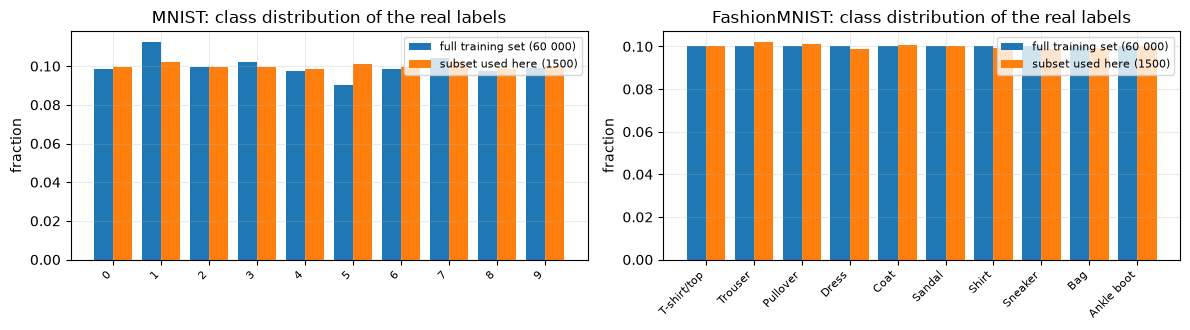

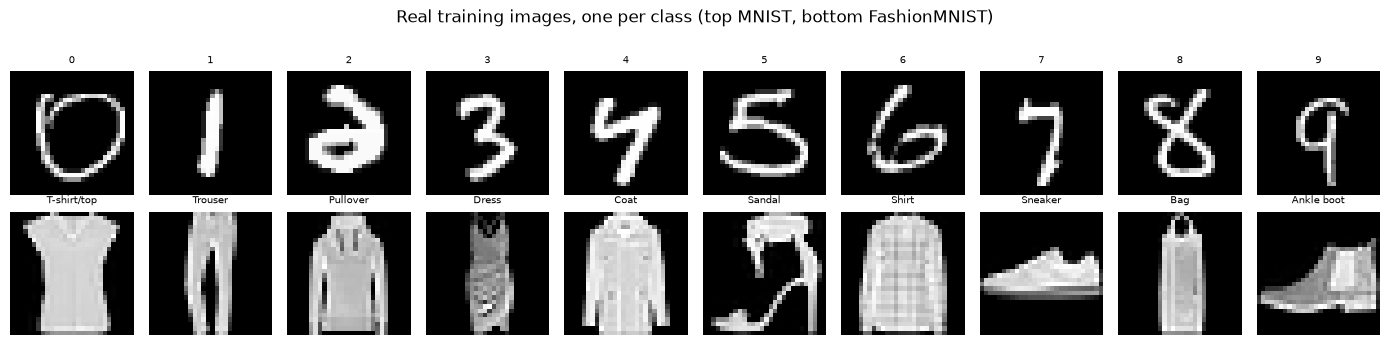

In [5]:
def strat_pick(y, n, rng_, pool=None):
    """Stratified random choice of n indices (as equal per class as possible) from the positions in `pool`."""
    pool = np.arange(len(y)) if pool is None else pool
    classes = np.unique(y[pool]); per = np.full(len(classes), n // len(classes)); per[: n - per.sum()] += 1
    idx = [rng_.permutation(pool[y[pool] == c])[:k] for c, k in zip(classes, per)]
    return rng_.permutation(np.concatenate(idx))

def to_t(x): return torch.tensor(x.astype(np.float64) / 255.0)

def make_split_qnn(ds, seed):
    """10-class 28x28 split: train / validation from the official train set, test from the official test set."""
    d = DATA[ds]; r = np.random.default_rng(seed)
    itv = strat_pick(d["y_train"], N_TRAIN_QNN + N_VAL_QNN, r)
    iva, itr = itv[:N_VAL_QNN], itv[N_VAL_QNN:]
    ite = strat_pick(d["y_test"], N_TEST_QNN, r)
    return {"train": (to_t(d["x_train"][itr]), torch.tensor(d["y_train"][itr])),
            "val":   (to_t(d["x_train"][iva]), torch.tensor(d["y_train"][iva])),
            "test":  (to_t(d["x_test"][ite]),  torch.tensor(d["y_test"][ite]))}

def downscale16(x):                     # (B,28,28) in [0,1] -> (B,256)
    return F.interpolate(x.unsqueeze(1), size=(16, 16), mode="bilinear", antialias=True, align_corners=False).squeeze(1).clamp(0, 1).reshape(len(x), 256)

def make_split_qc(ds, seed):
    """Binary 16x16 split (classes 0 and 1): the first two classes of each dataset, as in the paper."""
    d = DATA[ds]; r = np.random.default_rng(seed)
    ptr, pte = np.where(d["y_train"] < 2)[0], np.where(d["y_test"] < 2)[0]
    itv = strat_pick(d["y_train"], N_TRAIN_QC + N_VAL_QC, r, ptr)
    iva, itr = itv[:N_VAL_QC], itv[N_VAL_QC:]
    ite = strat_pick(d["y_test"], N_TEST_QC, r, pte)
    f = lambda x, y, i: (downscale16(to_t(x[i])), torch.tensor(y[i]))
    return {"train": f(d["x_train"], d["y_train"], itr), "val": f(d["x_train"], d["y_train"], iva), "test": f(d["x_test"], d["y_test"], ite)}

SPLIT_Q = {ds: make_split_qnn(ds, SEED) for ds in DATASETS}
SPLIT_B = {ds: make_split_qc(ds, SEED) for ds in DATASETS}
for ds in DATASETS:
    d = DATA[ds]
    print(f"=== {PRETTY[ds]} ===")
    print("full data      : train", d["x_train"].shape, "test", d["x_test"].shape)
    print("features       : 784 pixel intensities in [0,1] (28x28) per image; 256 after 16x16 down-scaling")
    print("original labels:", dict(zip(LABEL_NAMES[ds], np.bincount(d["y_train"]).tolist())), "(train counts)")
    print("QNN split      : train", tuple(SPLIT_Q[ds]["train"][0].shape), "val", tuple(SPLIT_Q[ds]["val"][0].shape), "test", tuple(SPLIT_Q[ds]["test"][0].shape),
          "| class counts train", np.bincount(SPLIT_Q[ds]["train"][1].numpy(), minlength=10).tolist())
    print("binary split   : train", tuple(SPLIT_B[ds]["train"][0].shape), "val", tuple(SPLIT_B[ds]["val"][0].shape), "test", tuple(SPLIT_B[ds]["test"][0].shape),
          "| classes", [LABEL_NAMES[ds][0], LABEL_NAMES[ds][1]], "| counts train", np.bincount(SPLIT_B[ds]["train"][1].numpy()).tolist())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, ds in zip(axes, DATASETS):
    full = np.bincount(DATA[ds]["y_train"], minlength=10); sub = np.bincount(SPLIT_Q[ds]["train"][1].numpy(), minlength=10)
    xs = np.arange(10); ax.bar(xs - 0.2, full / full.sum(), 0.4, label="full training set (60 000)"); ax.bar(xs + 0.2, sub / sub.sum(), 0.4, label=f"subset used here ({len(SPLIT_Q[ds]['train'][1])})")
    ax.set_xticks(xs); ax.set_xticklabels(LABEL_NAMES[ds], rotation=45, ha="right", fontsize=8); ax.set_ylabel("fraction"); ax.set_title(f"{PRETTY[ds]}: class distribution of the real labels"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for r_, ds in enumerate(DATASETS):
    x, y = SPLIT_Q[ds]["train"]
    for c in range(10):
        i = int(torch.where(y == c)[0][0]); axes[r_, c].imshow(x[i], cmap="gray"); axes[r_, c].axis("off"); axes[r_, c].set_title(LABEL_NAMES[ds][c], fontsize=7)
plt.suptitle("Real training images, one per class (top MNIST, bottom FashionMNIST)", y=1.02); plt.tight_layout(); plt.show()

MNIST QNN input: PCA explained variance of the two axes [0.094 0.071]
MNIST QCNN/VQC input: PCA explained variance of the two axes [0.406 0.105]


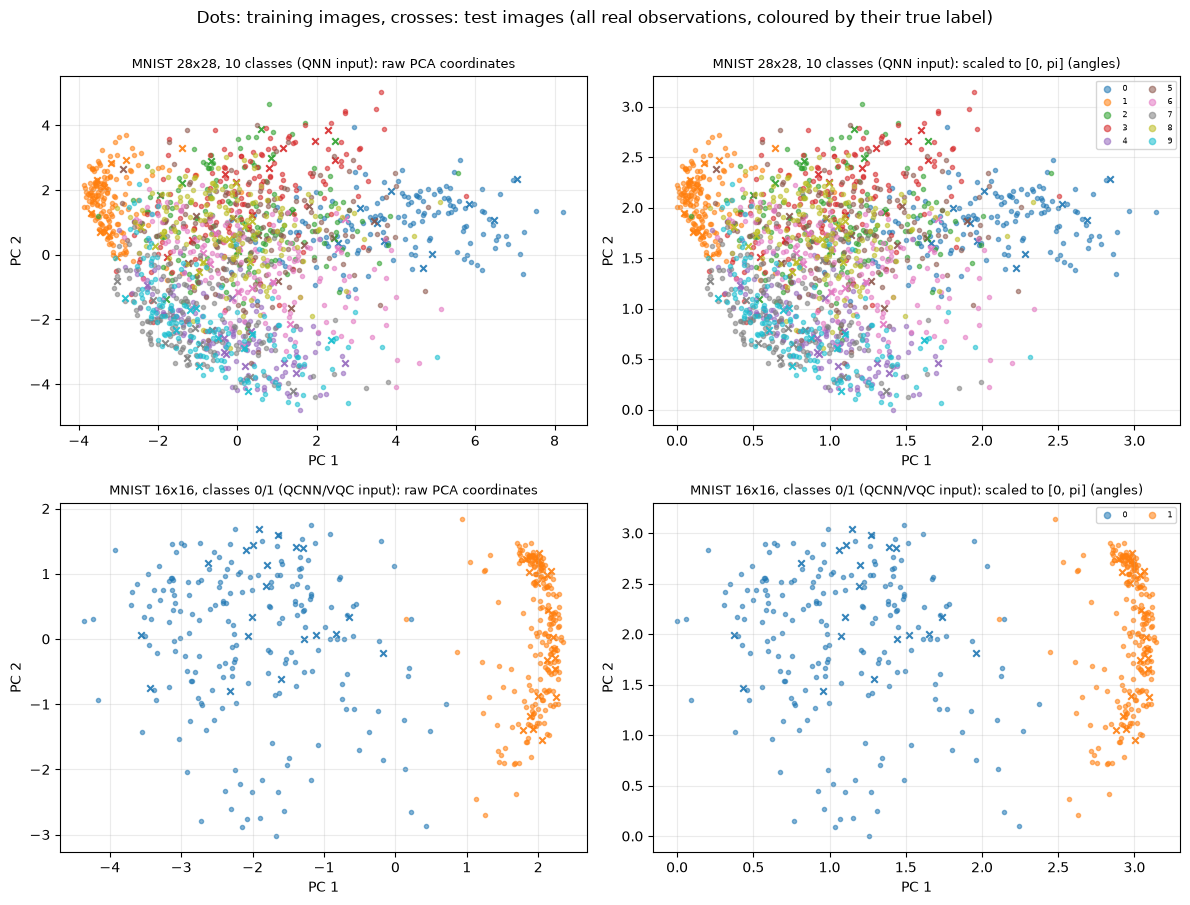

FashionMNIST QNN input: PCA explained variance of the two axes [0.288 0.18 ]
FashionMNIST QCNN/VQC input: PCA explained variance of the two axes [0.455 0.194]


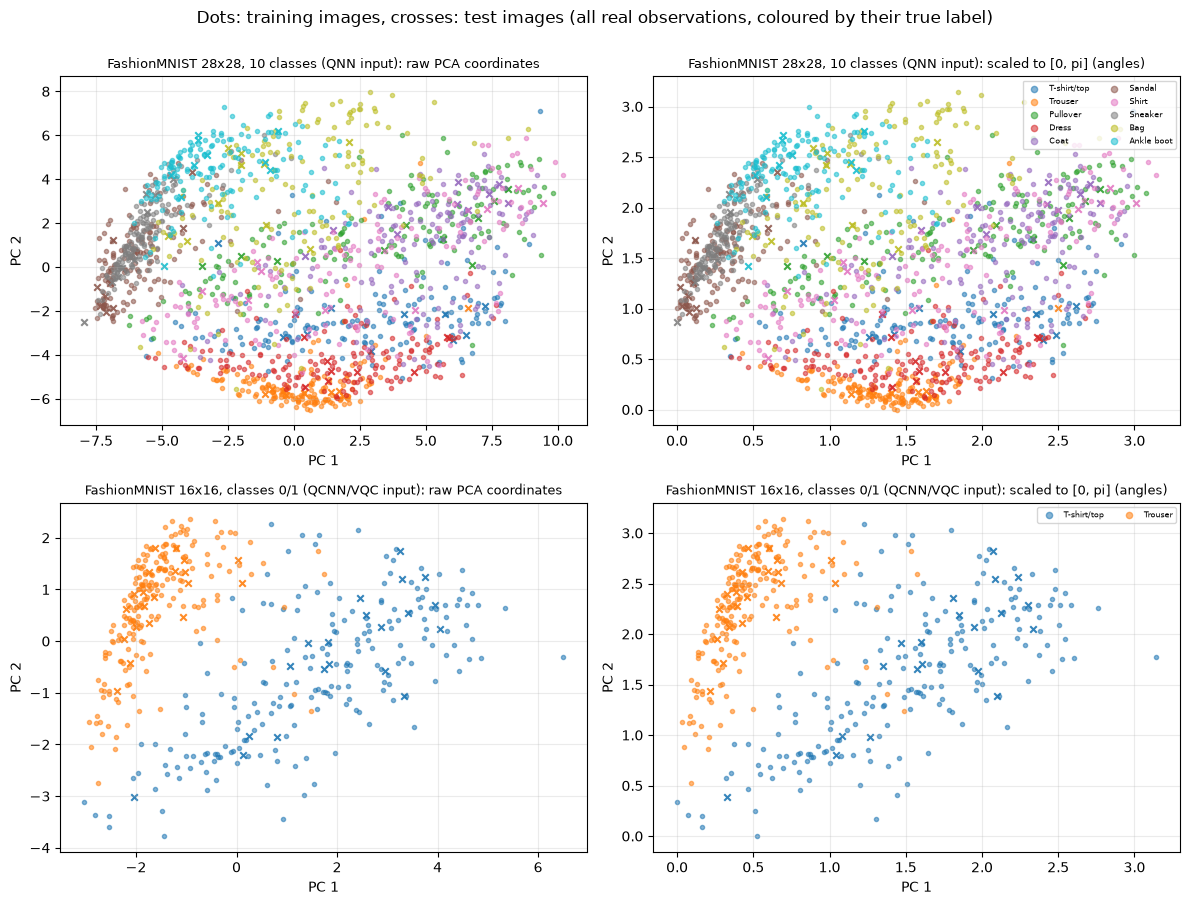

In [6]:
def class_scatter(ax_raw, ax_ang, Xtr, ytr, Xte, yte, names, title):
    """2-D PCA scatter of real observations coloured by ground-truth class (PCA / scaler fitted on the training split only)."""
    pca = PCA(n_components=2, random_state=SEED).fit(Xtr.numpy())
    Ztr, Zte = pca.transform(Xtr.numpy()), pca.transform(Xte.numpy())
    sc = MinMaxScaler((0, np.pi)).fit(Ztr)
    Atr, Ate = sc.transform(Ztr), np.clip(sc.transform(Zte), 0, np.pi)
    cmap = plt.get_cmap("tab10"); K = len(names)
    for ax, (A, B, lab) in zip((ax_raw, ax_ang), ((Ztr, Zte, "raw PCA coordinates"), (Atr, Ate, "scaled to [0, pi] (angles)"))):
        for c in range(K):
            m = ytr.numpy() == c; ax.scatter(A[m, 0], A[m, 1], s=9, color=cmap(c), alpha=0.55, label=names[c])
            m = yte.numpy() == c; ax.scatter(B[m, 0], B[m, 1], s=22, color=cmap(c), marker="x", alpha=0.9)
        ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); ax.set_title(f"{title}: {lab}", fontsize=9)
    ax_ang.legend(fontsize=6, ncol=2, markerscale=1.5, loc="best")
    return pca.explained_variance_ratio_

for ds in DATASETS:
    fig, axes = plt.subplots(2, 2, figsize=(12, 9))
    Xtr, ytr = SPLIT_Q[ds]["train"]; Xte, yte = SPLIT_Q[ds]["test"]
    ev = class_scatter(axes[0, 0], axes[0, 1], Xtr.reshape(len(Xtr), -1), ytr, Xte.reshape(len(Xte), -1), yte, LABEL_NAMES[ds], f"{PRETTY[ds]} 28x28, 10 classes (QNN input)")
    print(PRETTY[ds], "QNN input: PCA explained variance of the two axes", np.round(ev, 3))
    Xtr, ytr = SPLIT_B[ds]["train"]; Xte, yte = SPLIT_B[ds]["test"]
    ev = class_scatter(axes[1, 0], axes[1, 1], Xtr, ytr, Xte, yte, LABEL_NAMES[ds][:2], f"{PRETTY[ds]} 16x16, classes 0/1 (QCNN/VQC input)")
    print(PRETTY[ds], "QCNN/VQC input: PCA explained variance of the two axes", np.round(ev, 3))
    plt.suptitle("Dots: training images, crosses: test images (all real observations, coloured by their true label)", y=1.0); plt.tight_layout(); plt.show()

**What the scatter plots tell us.** Digit classes overlap strongly in two dimensions, FashionMNIST separates into footwear, trousers
and tops, and the binary 0/1 subsets are almost linearly separable. These two coordinates are only a picture: the models below
use all 784 (or 256) pixels. The scatter is not used by any model.

## 2. Passive steering in one qubit (the building block)

We first study the steering protocol on its own. The register is one qubit, the *system*, and the target state is the angle-encoded
state `|t(x)> = RY(x)|0>`. One round of the protocol is

1. rotate into the frame of the target, `RY(-x)` (the target becomes `|0>`, its orthogonal state becomes `|1>`),
2. couple system and ancilla with `U = exp(-i J (XX+YY)/2)` (a partial swap between `|1>_S|0>_A` and `|0>_S|1>_A`; the state
   `|0>_S|0>_A` is untouched, so the target is the fixed point),
3. rotate back, `RY(x)`,
4. measure the ancilla and reset it to `|0>`. Because the protocol is *passive* (no feedback on the measurement result), the
   state of the system is the average over both outcomes.

Starting from `|0>`, the population in the wrong state is multiplied by `cos^2(J)` in every round, so after `N` rounds the
fidelity with the target is

`F(x, J, N) = 1 - sin^2(x/2) * cos(J)^(2N)`.

With `J = pi/2` the target is reached in one round, and smaller `J` needs more rounds: exactly the behaviour of the paper's Fig. 7.
The intermediate state is **mixed**, the coherence between `|t>` and its orthogonal state is also damped, by `cos(J)^N`.
`N` rounds of the same channel are equal to **one** round with `cos(J_eff) = cos(J)^N`, which is how single-qubit steering is
run quickly below (an assertion in Section 3 checks it against the iterated circuit with real mid-circuit measurements).

The cell below re-draws Fig. 7 and checks the formula against the PennyLane circuit (mid-circuit measurement with reset).

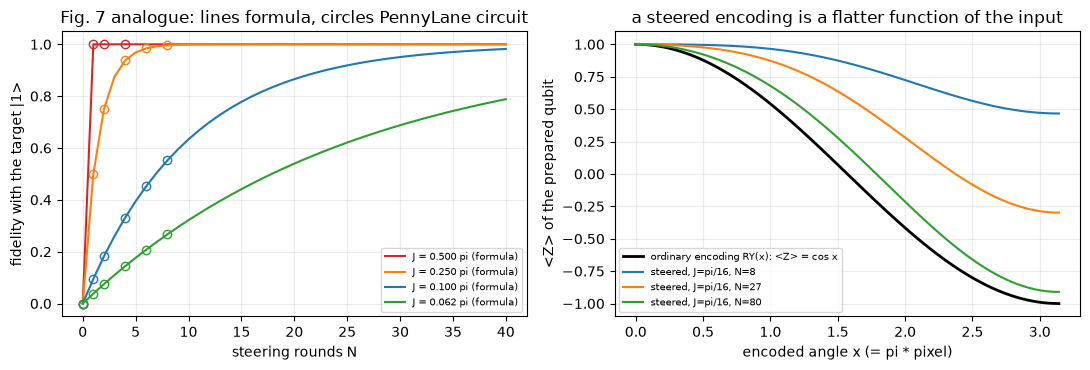

All PennyLane circuit values equal the closed form 1 - sin^2(x/2) cos(J)^(2N) to 1e-10.


In [7]:
def jeff(J, N):
    """J_eff such that ONE coupling of strength J_eff equals N rounds of strength J (measure + reset each round)."""
    return math.acos(math.cos(J) ** N)

def coupling_layer(J, n_sys):
    """Steering interaction exp(-i J (XX+YY)/2) of the ancilla (wire n_sys) with each system qubit in turn."""
    for k in range(n_sys):
        qml.IsingXX(J, wires=[k, n_sys]); qml.IsingYY(J, wires=[k, n_sys])

def steer1_explicit_circuit(x, J, N):
    """N rounds of single-qubit passive steering with REAL mid-circuit measurement and reset (system wire 0, ancilla wire 1)."""
    for _ in range(N):
        qml.RY(-x, wires=0); coupling_layer(J, 1); qml.RY(x, wires=0)
        qml.measure(1, reset=True)

def make_steer1_explicit(N):
    @qml.qnode(qml.device("default.qubit", wires=2 + N))
    def circ(x, J):
        steer1_explicit_circuit(x, J, N)
        qml.RY(-x, wires=0)                       # back to the frame of the target: the fidelity is P(system = |0>)
        return qml.expval(qml.Projector([0], wires=0))
    return circ

xs_demo = math.pi          # the target |1>: the farthest from the start state |0>
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
Ns = np.arange(0, 41)
for J, c in zip([math.pi / 2, math.pi / 4, math.pi / 10, math.pi / 16], ["C3", "C1", "C0", "C2"]):
    F_th = 1 - math.sin(xs_demo / 2) ** 2 * np.cos(J) ** (2 * Ns)
    ax[0].plot(Ns, F_th, color=c, label=f"J = {J / math.pi:.3f} pi (formula)")
    Nn = [0, 1, 2, 4, 6, 8] if J < math.pi / 3 else [0, 1, 2, 4]
    F_pl = [float(make_steer1_explicit(n)(xs_demo, J)) if n > 0 else 0.0 for n in Nn]
    ax[0].plot(Nn, F_pl, "o", color=c, mfc="none")
    for n, f in zip(Nn, F_pl):
        assert abs(f - (1 - math.sin(xs_demo / 2) ** 2 * math.cos(J) ** (2 * n))) < 1e-10, (J, n, f)
ax[0].set_xlabel("steering rounds N"); ax[0].set_ylabel("fidelity with the target |1>"); ax[0].set_title("Fig. 7 analogue: lines formula, circles PennyLane circuit"); ax[0].legend(fontsize=7)
@qml.qnode(qml.device("default.qubit", wires=2))
def steer1_fused_z(x, Je):           # N rounds fused into one coupling of strength Je, then <Z> of the system
    qml.RY(-x, wires=0); coupling_layer(Je, 1); qml.RY(x, wires=0)
    return qml.expval(qml.PauliZ(0))
xg = np.linspace(0, math.pi, 120); J = math.pi / 16
ax[1].plot(xg, np.cos(xg), "k", lw=2, label="ordinary encoding RY(x): <Z> = cos x")
for N_, c in zip([8, 27, 80], ["C0", "C1", "C2"]):
    ax[1].plot(xg, [float(steer1_fused_z(x, jeff(J, N_))) for x in xg], color=c, label=f"steered, J=pi/16, N={N_}")
ax[1].set_xlabel("encoded angle x (= pi * pixel)"); ax[1].set_ylabel("<Z> of the prepared qubit")
ax[1].set_title("a steered encoding is a flatter function of the input"); ax[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
print("All PennyLane circuit values equal the closed form 1 - sin^2(x/2) cos(J)^(2N) to 1e-10.")

## 3. The quantum circuits: definitions

Four kinds of circuits are needed. Each one is defined once, as a PennyLane QNode, and the **same** QNodes are drawn in the next
section and used by the experiments.

**QNN (hybrid, 4 qubits, one 2x2 patch per call).**
* *Baseline filter*: `RY(pi * pixel)` on each of the 4 qubits, one fixed random `StronglyEntanglingLayers` layer, `<Z>` of each
  qubit (the 4 feature maps).
* *Single-qubit steering*: every `RY` is replaced by the steering block of Section 2 with its own ancilla (8 qubits). The `N`
  rounds are fused into one coupling with `J_eff` (equal to the iterated circuit, asserted below).
* *Multi-qubit steering*: the four `RY` are replaced by **one** steering circuit with one ancilla (5 qubits). A round is
  `[RY(-x_k)]_k - [exp(-iJ(XX+YY)/2) with the ancilla]_k - [RY(x_k)]_k - measure and reset the ancilla`. The fixed point is the
  product state `RY(x_1)...RY(x_4)|0000>`. Rounds do not fuse, so they are simulated exactly with the one-round channel (Kraus
  operators read from the PennyLane circuit), which is again checked against PennyLane's mixed-state simulator.

**VQC and QCNN (fully quantum, 8 qubits).** Amplitude embedding of the 16x16 image, then `StronglyEntanglingLayers` (VQC) or
convolution/pooling blocks (QCNN), then `<Z>` of the last qubit. **Amplitude steering**: the encoding unitary `V(x)` (a Householder
reflection, `V|0...0> = image`) is wrapped around the same multi-qubit steering interaction with one ancilla:
`[V(x) - coupling to the ancilla (8 pairs) - V(x)^dagger - measure and reset]` repeated `N` times, then the classifier.

In [8]:
# ---------------- QNN circuits ----------------
NQ = 4
_r = np.random.default_rng(SEED)
FILTER_W = torch.tensor(_r.uniform(0, 2 * np.pi, size=(1, NQ, 3)))     # CHOICE: fixed random quantum filter (12 angles), NOT trained

def filter_circuit():
    qml.StronglyEntanglingLayers(FILTER_W, wires=range(NQ))

@qml.qnode(qml.device("default.qubit", wires=NQ), interface="torch", diff_method="backprop")
def base_qnode(a):
    """Baseline quanvolution filter. a: 4 angles (or a batch (P,4), PennyLane broadcasting)."""
    for k in range(NQ):
        qml.RY(a[..., k], wires=k)
    filter_circuit()
    return [qml.expval(qml.PauliZ(k)) for k in range(NQ)]

@qml.qnode(qml.device("default.qubit", wires=2 * NQ), interface="torch", diff_method="backprop")
def steer1_qnode(a, Je):
    """Single-qubit steering filter: N rounds fused into one coupling of strength Je = jeff(J, N); ancilla k is wire NQ+k."""
    for k in range(NQ):
        qml.RY(-a[..., k], wires=k); coupling_pair(Je, k, NQ + k); qml.RY(a[..., k], wires=k)
    filter_circuit()
    return [qml.expval(qml.PauliZ(k)) for k in range(NQ)]

def coupling_pair(J, s, anc):
    qml.IsingXX(J, wires=[s, anc]); qml.IsingYY(J, wires=[s, anc])

RESET_KRAUS = [np.array([[1, 0], [0, 0]], dtype=complex), np.array([[0, 1], [0, 0]], dtype=complex)]   # |0><0| and |0><1|

def reset_ancilla(wire, mode):
    if mode == "measure":
        qml.measure(wire, reset=True)                 # real mid-circuit measurement + reset (deferred-measurement simulator)
    else:
        qml.QubitChannel(RESET_KRAUS, wires=wire)     # the same average over outcomes as a channel (mixed-state simulator)

def steer1_full_explicit(a, J, N, mode="measure"):
    """Reference semantics of single-qubit steering: N rounds, each qubit with its own ancilla, measure + reset every round."""
    for _ in range(N):
        for k in range(NQ):
            qml.RY(-a[k], wires=k); coupling_pair(J, k, NQ + k); qml.RY(a[k], wires=k); reset_ancilla(NQ + k, mode)
    filter_circuit()
    return [qml.expval(qml.PauliZ(k)) for k in range(NQ)]

def multi_explicit(a, J, N, mode="measure"):
    """Reference semantics of multi-qubit steering: N rounds, ONE ancilla (wire NQ), measure + reset every round."""
    for _ in range(N):
        for k in range(NQ): qml.RY(-a[k], wires=k)
        coupling_layer(J, NQ)
        for k in range(NQ): qml.RY(a[k], wires=k)
        reset_ancilla(NQ, mode)
    filter_circuit()
    return [qml.expval(qml.PauliZ(k)) for k in range(NQ)]

# --- executor of multi-qubit steering: the one-round channel (Kraus operators from the PennyLane circuit) ---
def one_round_kraus(J, n_sys):
    U = qml.matrix(coupling_layer, wire_order=list(range(n_sys + 1)))(J, n_sys)
    d = 2 ** n_sys; U = U.reshape(d, 2, d, 2)
    return U[:, 0, :, 0], U[:, 1, :, 0]                  # K0 = <0|U|0>_A, K1 = <1|U|0>_A  (ancilla starts in |0>)

K0m, K1m = [torch.tensor(K) for K in one_round_kraus(J_QNN, NQ)]
assert torch.allclose(K0m.conj().T @ K0m + K1m.conj().T @ K1m, torch.eye(16, dtype=K0m.dtype))     # trace preserving
SUPER_M = torch.kron(K0m, K0m.conj()) + torch.kron(K1m, K1m.conj())                            # superoperator on row-major vec(rho)
_PW = {}
def super_power(N):
    if N not in _PW: _PW[N] = torch.linalg.matrix_power(SUPER_M, N)
    return _PW[N]

_Wf = torch.tensor(qml.matrix(filter_circuit, wire_order=list(range(NQ)))())
def _zk(k):
    ops = [torch.eye(2)] * NQ; ops[k] = torch.diag(torch.tensor([1.0, -1.0])); m = ops[0]
    for o in ops[1:]: m = torch.kron(m, o)
    return m.to(_Wf.dtype)
OBS_FILTER = torch.stack([_Wf.conj().T @ _zk(k) @ _Wf for k in range(NQ)])        # (4,16,16): <Z_k> after the filter = Tr[O_k rho]

def _ry(x):
    c, s = torch.cos(x / 2), torch.sin(x / 2)
    return torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2)
def _kron_mats(mats):
    out = mats[0]
    for m in mats[1:]:
        out = torch.einsum("bij,bkl->bikjl", out, m).reshape(out.shape[0], out.shape[1] * m.shape[1], out.shape[2] * m.shape[2])
    return out
def _kron_vecs(vs):
    out = vs[0]
    for v in vs[1:]:
        out = torch.einsum("bi,bj->bij", out, v).reshape(out.shape[0], -1)
    return out

def multi_features(a, N):
    """Multi-qubit steering + filter for a batch of patches a (P,4): exact N-round channel, <Z_k> of the 4 filter outputs."""
    P = a.shape[0]
    phi = _kron_vecs([torch.stack([torch.cos(a[:, k] / 2), -torch.sin(a[:, k] / 2)], -1) for k in range(NQ)]).to(torch.complex128)   # V^dagger|0000>
    rho = torch.einsum("bi,bj->bij", phi, phi.conj()).reshape(P, 256) @ super_power(N).T                                              # N rounds in the target frame
    V = _kron_mats([_ry(a[:, k]) for k in range(NQ)]).to(torch.complex128)
    rho = V @ rho.reshape(P, 16, 16) @ V.conj().transpose(1, 2)                                                                       # back to the lab frame
    return torch.einsum("jab,nba->nj", OBS_FILTER, rho).real

print("single-qubit steering executor : fused J_eff circuit (8 qubits)")
print("multi-qubit steering executor  : exact one-round channel, Kraus rank", 2, "| superoperator", tuple(SUPER_M.shape))

single-qubit steering executor : fused J_eff circuit (8 qubits)
multi-qubit steering executor  : exact one-round channel, Kraus rank 2 | superoperator (256, 256)


In [9]:
# ---------------- fully quantum circuits: VQC, QCNN, amplitude steering ----------------
NQA = 8
dev_a = qml.device("default.qubit", wires=NQA)

def vqc_body(w):
    qml.StronglyEntanglingLayers(w, wires=range(NQA))

def conv_block(p, a, b):      # CHOICE: 3 angles per two-qubit block
    qml.RY(p[0], wires=a); qml.RY(p[1], wires=b); qml.CNOT(wires=[a, b]); qml.RY(p[2], wires=b)

def pool_block(p, a, b):      # CHOICE: pools qubit a into qubit b (a is discarded afterwards), 3 angles
    qml.CRZ(p[0], wires=[a, b]); qml.PauliX(wires=a); qml.CRX(p[1], wires=[a, b]); qml.RY(p[2], wires=b)

def qcnn_body(cw, pw):
    """3 stages: 8 -> 4 -> 2 -> 1 active qubits. Stage s: a ring of conv blocks on the active qubits, then pooling of every pair."""
    ci = pi_ = 0; act = list(range(NQA))
    for _ in range(3):
        n = len(act)
        for i in range(n):
            a, b = (act[i], act[(i + 1) % n]) if not (n == 2 and i == 1) else (act[1], act[0])
            conv_block(cw[ci], a, b); ci += 1
        keep = []
        for i in range(0, n, 2):
            pool_block(pw[pi_], act[i], act[i + 1]); pi_ += 1; keep.append(act[i + 1])
        act = keep
    return ci, pi_

@qml.qnode(dev_a, interface="torch", diff_method="backprop")
def vqc_qnode(x, w):
    qml.AmplitudeEmbedding(x, wires=range(NQA), normalize=True)
    vqc_body(w)
    return qml.expval(qml.PauliZ(NQA - 1))

@qml.qnode(dev_a, interface="torch", diff_method="backprop")
def qcnn_qnode(x, cw, pw):
    qml.AmplitudeEmbedding(x, wires=range(NQA), normalize=True)
    qcnn_body(cw, pw)
    return qml.expval(qml.PauliZ(NQA - 1))

N_CONV, N_POOL = 14, 7            # blocks of the QCNN layout above
print("QCNN trainable parameters:", 3 * N_CONV, "(conv) +", 3 * N_POOL, "(pool) =", 3 * (N_CONV + N_POOL), "| VQC trainable parameters:", 3 * NQA * 3)

# --- amplitude steering: Householder encoding unitary, reference circuit and exact executor ---
def householder(psi):
    """V with V|0...0> = psi (psi: (B,256) real unit vectors): V = I - 2uu^T/(u^T u), u = e0 - psi. V is symmetric and V V = I."""
    B, d = psi.shape; e0 = torch.zeros(d); e0[0] = 1
    u = e0 - psi; nu = (u * u).sum(1)
    I = torch.eye(d).expand(B, d, d)
    Hm = I - 2 * u[:, :, None] * u[:, None, :] / nu.clamp_min(1e-30)[:, None, None]
    return torch.where((nu < 1e-20)[:, None, None], I, Hm)

def amp_steer_reference(Vmat, J, N, body, mode="measure"):
    """Reference circuit: N rounds of  V - [8 couplings with the single ancilla (wire 8)] - V^dagger - measure + reset, then the classifier."""
    for _ in range(N):
        qml.QubitUnitary(Vmat.T, wires=range(NQA))               # V^dagger (rotate into the frame of the target)
        coupling_layer(J, NQA)
        qml.QubitUnitary(Vmat, wires=range(NQA))                 # V
        reset_ancilla(NQA, mode)
    body()
    return qml.expval(qml.PauliZ(NQA - 1))

class AmpSteer:
    """Exact N-round amplitude steering of a batch of images: rho_N = V Phi^N(V^dagger|0><0|V) V^dagger, evaluated on the fly."""
    def __init__(self, J):
        K0, K1 = one_round_kraus(J, NQA)
        self.K = [torch.tensor(K).to(torch.complex64) for K in (K0, K1)]; self.Kst = torch.cat(self.K, 0)
    def _round(self, rho):
        B, d = rho.shape[0], 256
        R = rho.permute(1, 0, 2).reshape(d, B * d)
        A = (self.Kst @ R).reshape(2, d, B, d)
        Ah = A.conj().permute(0, 3, 2, 1)                       # (K rho)^dagger = rho K^dagger
        out = 0
        for a in range(2):
            out = out + (self.K[a] @ Ah[a].reshape(d, B * d)).reshape(d, B, d).permute(1, 0, 2)
        return out
    def run(self, psi, obs, n_record, batch=20):
        """psi (B,256) unit vectors, obs (M,256,256) complex64 observables, n_record: iterable of N. Returns {N: (B,M) expectations}."""
        n_record = sorted(set(int(n) for n in n_record)); res = {n: [] for n in n_record}
        for s in range(0, len(psi), batch):
            p = psi[s:s + batch]; Hm = householder(p).to(torch.complex64)
            rho = torch.einsum("bi,bj->bij", p, p).to(torch.complex64)        # V^dagger|0> = psi because V is an involution
            for it in range(1, n_record[-1] + 1):
                rho = self._round(rho)
                if it in res:
                    lab = Hm @ rho @ Hm
                    res[it].append(torch.einsum("mab,nba->nm", obs, lab).real.to(torch.float64))
        return {n: torch.cat(v) for n, v in res.items()}

def body_matrix(body):
    """Unitary of a classifier body acting on the 8 qubits, and its observable O = W^dagger Z_last W (so <Z> = Tr[O rho])."""
    W = torch.tensor(qml.matrix(body, wire_order=list(range(NQA)))()).to(torch.complex64)
    Z = torch.kron(torch.eye(128), torch.diag(torch.tensor([1.0, -1.0]))).to(torch.complex64)
    return W.conj().T @ Z @ W
print("amplitude steering executor ready (Householder encoding unitary, complex64 density matrices of 256 x 256)")

QCNN trainable parameters: 42 (conv) + 21 (pool) = 63 | VQC trainable parameters: 72
amplitude steering executor ready (Householder encoding unitary, complex64 density matrices of 256 x 256)


## Quantum Circuit Architecture

Below, every gate-based quantum model the notebook trains or evaluates is drawn with `qml.draw_mpl` from the **QNode that is
executed**, one drawing per distinct architecture:

1. the baseline quanvolution filter (4 qubits),
2. the single-qubit-steering filter that the experiments execute (8 qubits, `N` rounds fused),
3. the reference form of single-qubit steering with real mid-circuit measurement and reset (shown for `N = 2` rounds, 2 x 4 ancilla
   resets), which defines the semantics the fused circuit must equal,
4. the multi-qubit-steering reference circuit (one ancilla, `N = 2`),
5. the VQC, 6. the QCNN, 7. the amplitude-steering reference circuit (9 qubits, `N = 2`, followed by the VQC body).

Assumptions where the paper omits circuit details (see the table in the introduction): the quantum filter angles, the Hamiltonian
`(XX+YY)/2` of the steering unitary, the product ordering of the couplings in the multi-qubit round, the Householder form of the
amplitude-encoding unitary, the QCNN blocks. The angles drawn for VQC / QCNN are the seeded initial values; training changes only
these angle values, not the architecture. For each circuit the qubit count, the circuit depth and the number of trainable
parameters are printed.

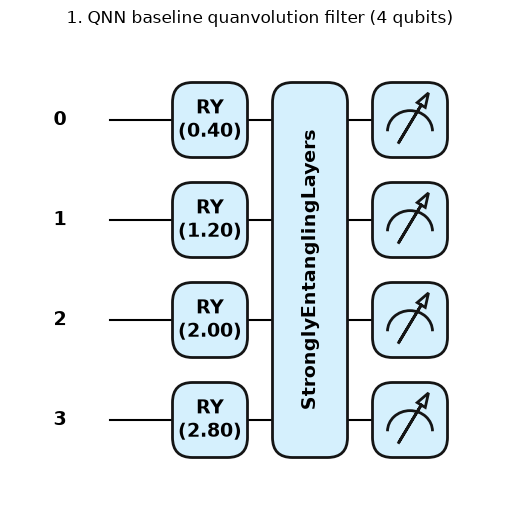

1. QNN baseline filter                                     qubits=  4 depth=   6 trainable parameters=  0 (12 fixed filter angles, not trained)


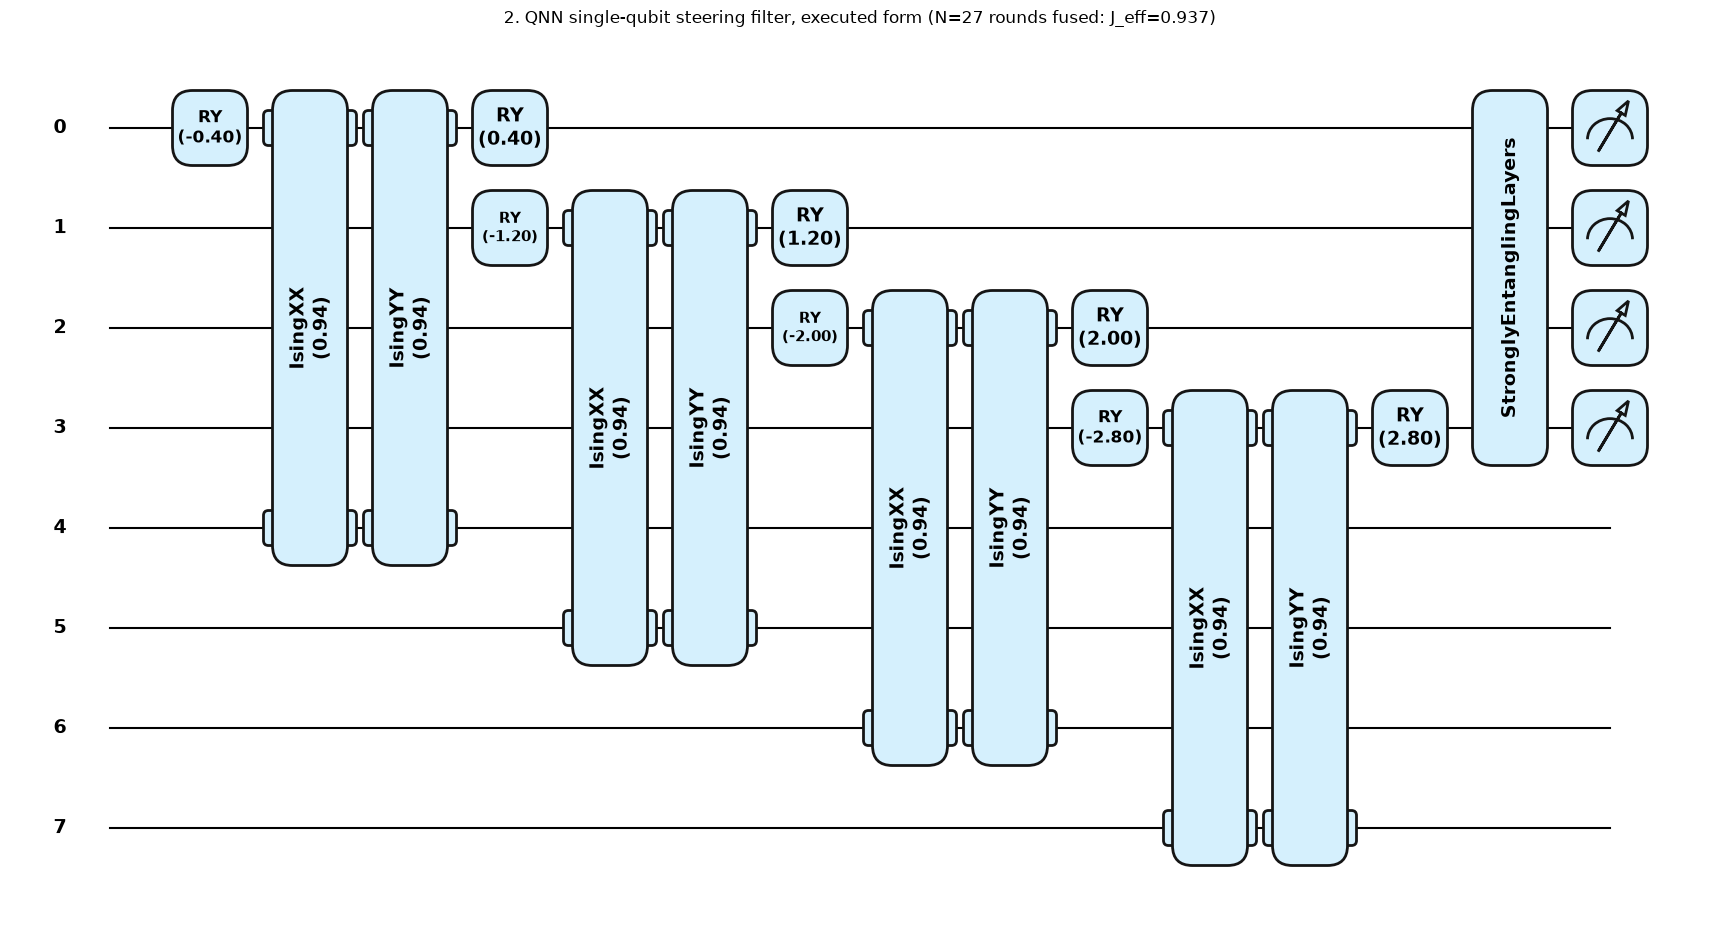

2. QNN single-qubit steering (fused)                       qubits=  8 depth=   9 trainable parameters=  0 (defence adds no trainable parameter)


In [10]:
def stats(name, qn, *args, trainable=0, note=""):
    tape = qml.workflow.construct_batch(qn, level=0)(*args)[0][0]
    nq = len(tape.wires)                                    # qubits used (system + ancillas)
    try:
        depth = qml.specs(qn, level="device")(*args)["resources"].depth          # depth after decomposition to gates
    except Exception:
        depth = qml.specs(qn)(*args)["resources"].depth
    print(f"{name:58s} qubits={nq!s:>3} depth={depth!s:>4} trainable parameters={trainable:>3} {note}")

a_demo = torch.tensor([0.4, 1.2, 2.0, 2.8])
J_demo, N_demo = J_QNN, 27
x16 = SPLIT_B["mnist"]["train"][0][:1]
torch.manual_seed(SEED)
w_vqc0 = 0.1 * torch.randn(3, NQA, 3); cw0 = 0.3 * torch.randn(N_CONV, 3); pw0 = 0.3 * torch.randn(N_POOL, 3)
psi_demo = x16 / x16.norm(dim=1, keepdim=True); V_demo = householder(psi_demo)[0]

figs = []
fig, _ = qml.draw_mpl(base_qnode, decimals=2, style="pennylane")(a_demo); fig.suptitle("1. QNN baseline quanvolution filter (4 qubits)", y=1.02); plt.show()
stats("1. QNN baseline filter", base_qnode, a_demo, trainable=0, note="(12 fixed filter angles, not trained)")
fig, _ = qml.draw_mpl(steer1_qnode, decimals=2, style="pennylane")(a_demo, jeff(J_demo, N_demo)); fig.suptitle(f"2. QNN single-qubit steering filter, executed form (N={N_demo} rounds fused: J_eff={jeff(J_demo, N_demo):.3f})", y=1.02); plt.show()
stats("2. QNN single-qubit steering (fused)", steer1_qnode, a_demo, jeff(J_demo, N_demo), trainable=0, note="(defence adds no trainable parameter)")

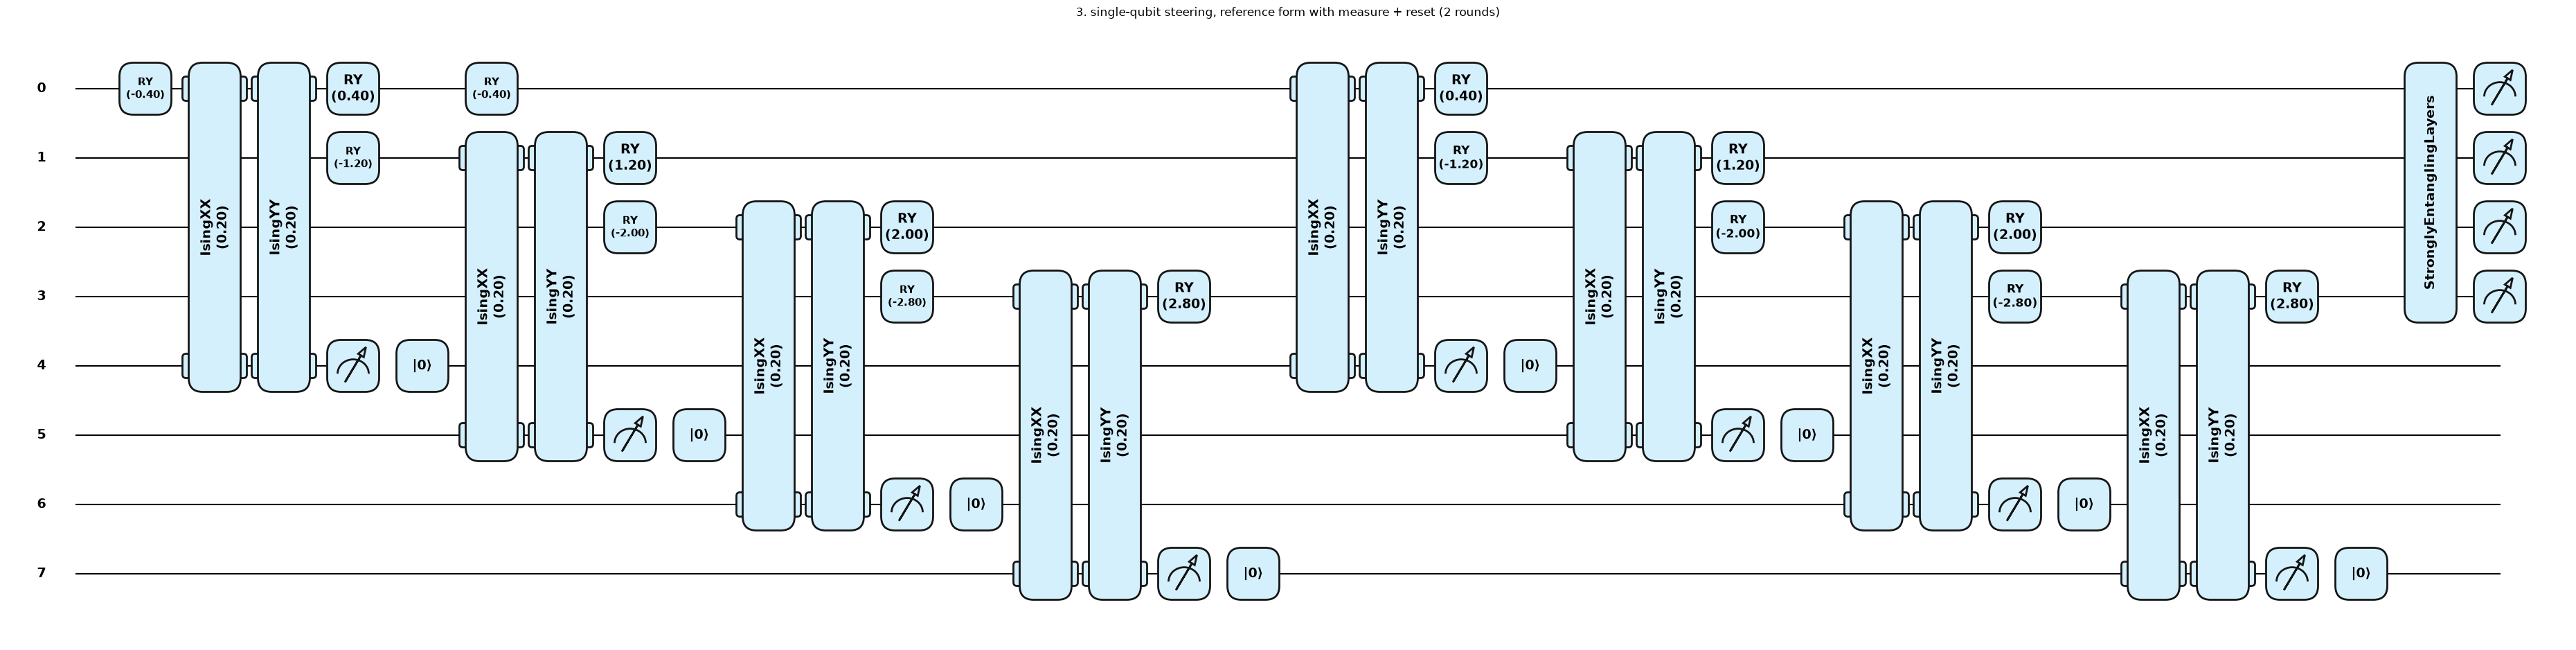

3. single-qubit steering reference (N=2)                   qubits=  8 depth=  13 trainable parameters=  0 


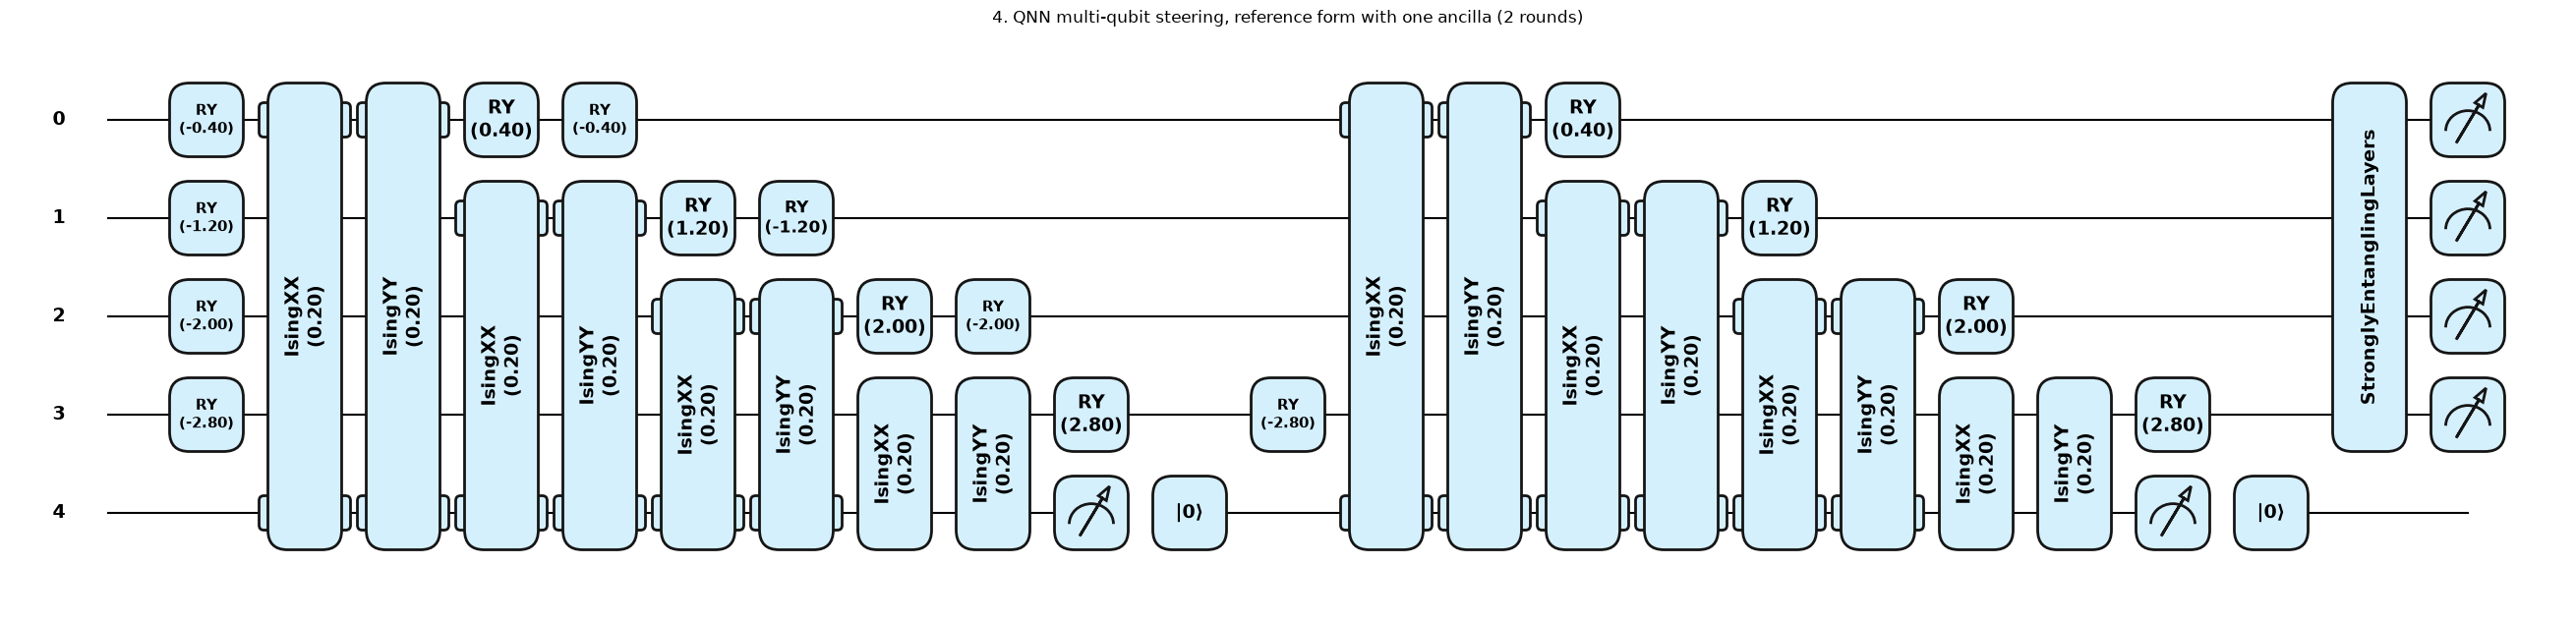

4. multi-qubit steering reference (N=2)                    qubits=  5 depth=  23 trainable parameters=  0 


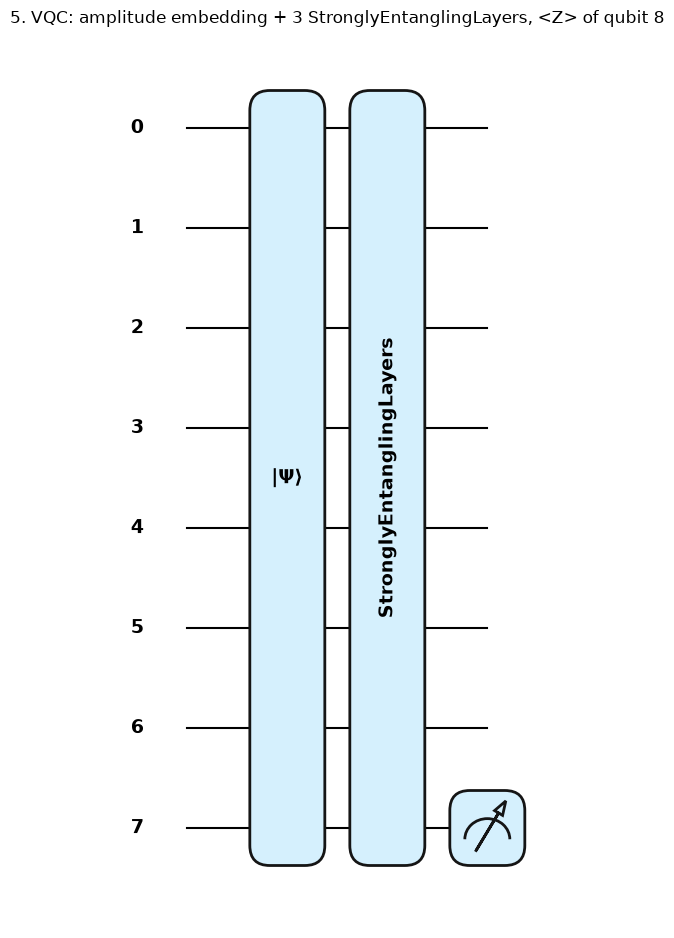

5. VQC                                                     qubits=  8 depth=  19 trainable parameters= 72 


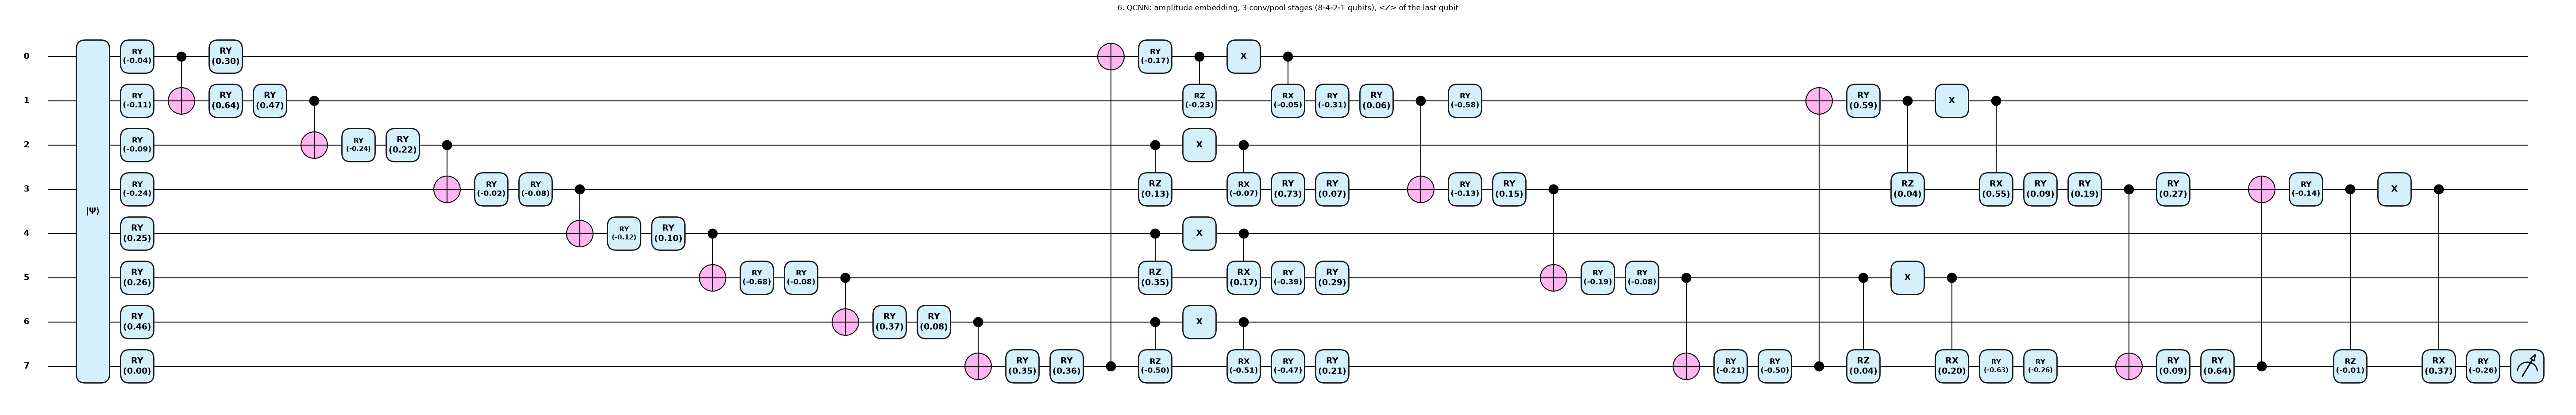

6. QCNN                                                    qubits=  8 depth=  55 trainable parameters= 63 


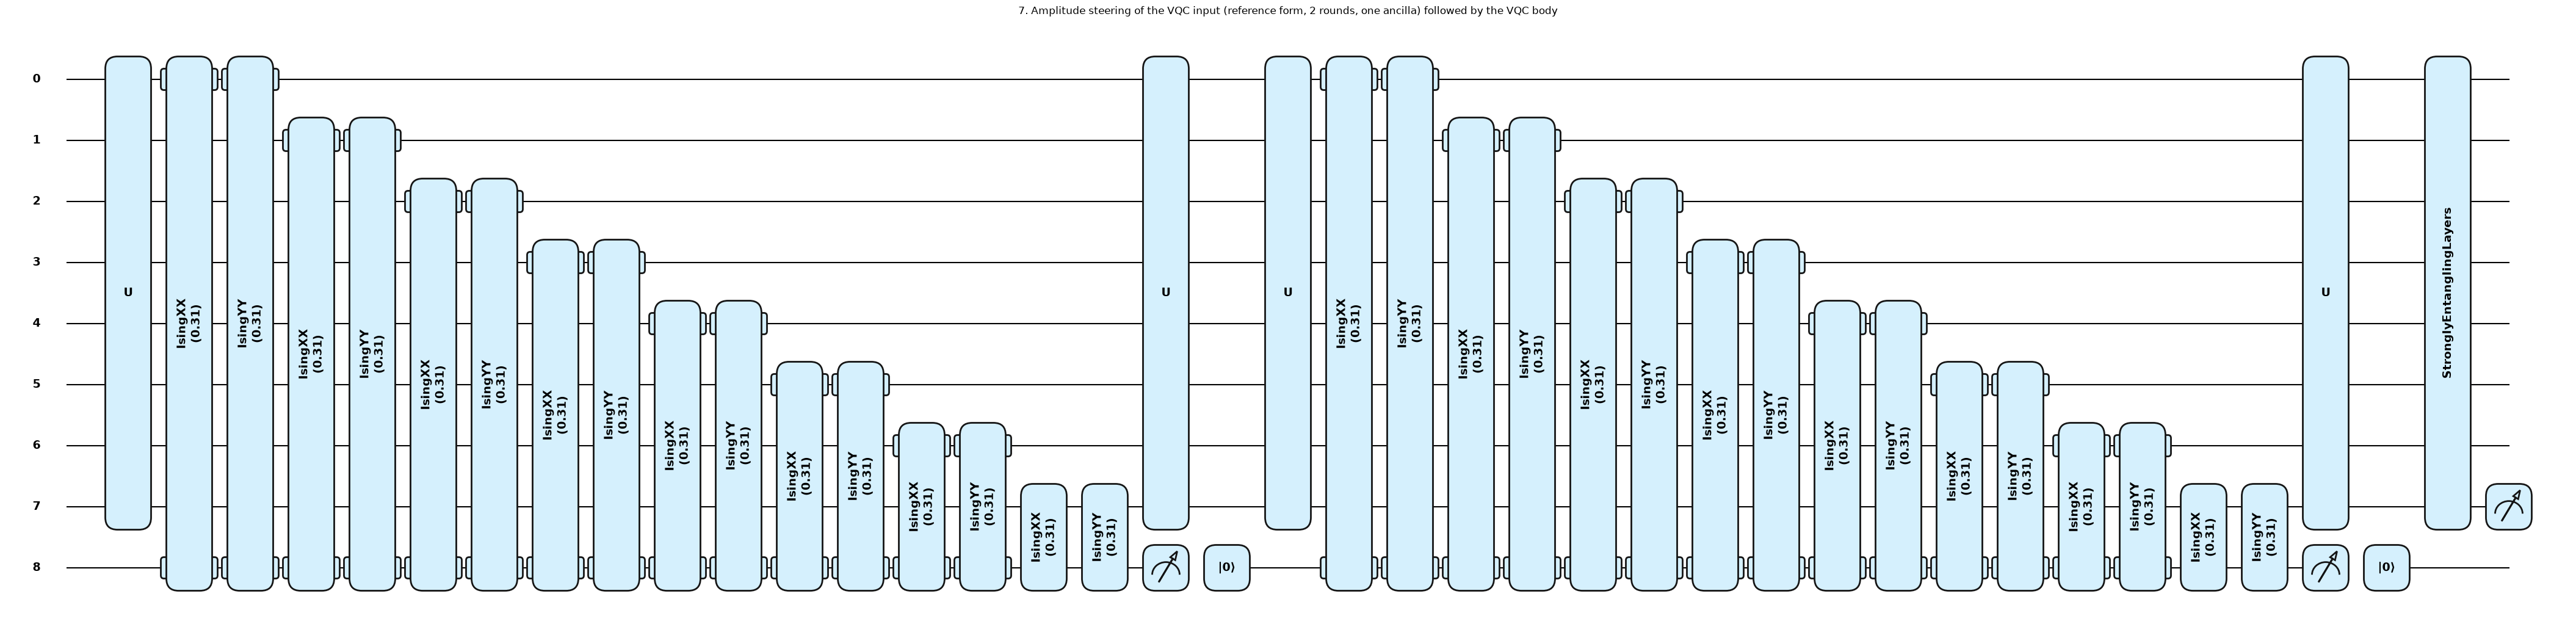

7. amplitude steering + VQC (N=2)                          qubits=  9 depth=  54 trainable parameters= 72 (steering adds none)


In [11]:
N_DRAW = 2
dev_ref1 = qml.device("default.qubit", wires=2 * NQ + N_DRAW * NQ)
ref1 = qml.QNode(lambda a, J: steer1_full_explicit(a, J, N_DRAW, "measure"), dev_ref1)
fig, _ = qml.draw_mpl(ref1, decimals=2, style="pennylane")(a_demo, J_demo); fig.suptitle(f"3. single-qubit steering, reference form with measure + reset ({N_DRAW} rounds)", y=1.02); plt.show()
stats("3. single-qubit steering reference (N=2)", ref1, a_demo, J_demo, trainable=0)

dev_ref2 = qml.device("default.qubit", wires=NQ + 1 + N_DRAW)
ref2 = qml.QNode(lambda a, J: multi_explicit(a, J, N_DRAW, "measure"), dev_ref2)
fig, _ = qml.draw_mpl(ref2, decimals=2, style="pennylane")(a_demo, J_demo); fig.suptitle(f"4. QNN multi-qubit steering, reference form with one ancilla ({N_DRAW} rounds)", y=1.02); plt.show()
stats("4. multi-qubit steering reference (N=2)", ref2, a_demo, J_demo, trainable=0)

fig, _ = qml.draw_mpl(vqc_qnode, decimals=2, style="pennylane")(x16[0], w_vqc0); fig.suptitle("5. VQC: amplitude embedding + 3 StronglyEntanglingLayers, <Z> of qubit 8", y=1.02); plt.show()
stats("5. VQC", vqc_qnode, x16[0], w_vqc0, trainable=w_vqc0.numel())
fig, _ = qml.draw_mpl(qcnn_qnode, decimals=2, style="pennylane")(x16[0], cw0, pw0); fig.suptitle("6. QCNN: amplitude embedding, 3 conv/pool stages (8-4-2-1 qubits), <Z> of the last qubit", y=1.02); plt.show()
stats("6. QCNN", qcnn_qnode, x16[0], cw0, pw0, trainable=cw0.numel() + pw0.numel())

dev_ref3 = qml.device("default.qubit", wires=NQA + 1 + N_DRAW)
ref3 = qml.QNode(lambda V, J: amp_steer_reference(V, J, N_DRAW, lambda: vqc_body(w_vqc0), "measure"), dev_ref3)
fig, _ = qml.draw_mpl(ref3, decimals=2, style="pennylane")(V_demo, J_QC); fig.suptitle("7. Amplitude steering of the VQC input (reference form, 2 rounds, one ancilla) followed by the VQC body", y=1.02); plt.show()
stats("7. amplitude steering + VQC (N=2)", ref3, V_demo, J_QC, trainable=w_vqc0.numel(), note="(steering adds none)")

### Are the fast executors the same as the reference circuits?

The experiments run thousands of images, so they use the fused single-qubit circuit and the exact Kraus-channel executors. The
cell below asserts that they equal the reference circuits drawn above (real mid-circuit measurement and reset in
`default.qubit`, and the explicit reset channel in `default.mixed`), for several inputs and several `N`.

In [12]:
rs = np.random.default_rng(SEED)
# (a) single-qubit steering: fused J_eff circuit == N rounds with real measurement + reset  (4 qubits + 4 ancillas, N = 2)
for _ in range(3):
    a = torch.tensor(rs.uniform(0, np.pi, NQ))
    ref = torch.stack(ref1(a, J_demo)); fused = torch.stack(steer1_qnode(a, jeff(J_demo, N_DRAW)))
    assert torch.allclose(ref, fused, atol=1e-10), (ref, fused)
# (a2) larger N with the mixed-state simulator (reset channel), 1 qubit-ancilla pair per qubit, N = 27
dev_m8 = qml.device("default.mixed", wires=2 * NQ)
ref1_mixed = qml.QNode(lambda a, J, N: steer1_full_explicit(a, J, N, "channel"), dev_m8)
a = torch.tensor(rs.uniform(0, np.pi, NQ))
assert torch.allclose(torch.stack(ref1_mixed(a.numpy(), J_demo, 27)), torch.stack(steer1_qnode(a, jeff(J_demo, 27))), atol=1e-8)
# (b) multi-qubit steering: exact N-round channel executor == measure/reset circuit (N=2) and == reset-channel circuit (N = 6 and 40)
dev_m5 = qml.device("default.mixed", wires=NQ + 1)
ref2_mixed = qml.QNode(lambda a, J, N: multi_explicit(a, J, N, "channel"), dev_m5)
for _ in range(3):
    a = torch.tensor(rs.uniform(0, np.pi, NQ))
    assert torch.allclose(torch.stack(ref2(a, J_demo)), multi_features(a[None], N_DRAW)[0], atol=1e-10)
    for N_ in (6, 40):
        assert torch.allclose(torch.tensor(np.array(ref2_mixed(a.numpy(), J_demo, N_))), multi_features(a[None], N_)[0], atol=1e-8)
print("single-qubit: fused J_eff circuit  ==  measure+reset circuit (N=2, 3 inputs)  ==  reset-channel circuit (N=27)")
print("multi-qubit : Kraus-channel executor  ==  measure+reset circuit (N=2)  ==  reset-channel circuit (N=6, 40)")

single-qubit: fused J_eff circuit  ==  measure+reset circuit (N=2, 3 inputs)  ==  reset-channel circuit (N=27)
multi-qubit : Kraus-channel executor  ==  measure+reset circuit (N=2)  ==  reset-channel circuit (N=6, 40)


## 4. The hybrid quanvolutional network (QNN)

**Pipeline.** A 28x28 image in `[0,1]` is cut into 196 non-overlapping 2x2 patches. Each patch is encoded in 4 qubits with
`RY(pi * pixel)`, passed through the fixed quantum filter and read out with `<Z>` on each qubit, giving 4 numbers per patch, i.e.
**4 feature maps of 14x14**. A classical network (CONV1-POOL1-CONV2-POOL2-FC1-FC2) classifies the 10 classes.

Because the quantum filter is fixed, the 4 feature maps of the training images are computed once and only the classical head is
trained. For the attacks, gradients are propagated back through the quantum filter to the pixels (PennyLane back-propagation on
the state-vector simulator). The identical head, **trained once and never retrained**, is evaluated behind each encoder:
the ordinary one, single-qubit steering (S) and multi-qubit steering (M).

In [13]:
def to_patches(x):
    """(B,28,28) pixels in [0,1] -> (B*196, 4) angles pi * pixel; qubit k of a patch carries pixel k of the 2x2 patch.  # CHOICE: pi * pixel"""
    p = F.unfold(x.unsqueeze(1), kernel_size=2, stride=2)          # (B,4,196)
    return math.pi * p.permute(0, 2, 1).reshape(-1, 4)

def qfeat(x, mode="base", par=None, grad=False):
    """Quanvolution feature maps (B,4,14,14). mode: base (ordinary RY), S (single-qubit steering, par = J_eff), M (multi-qubit steering, par = N)."""
    B = x.shape[0]; a = to_patches(x)
    def f(ai):
        if mode == "base": return torch.stack(base_qnode(ai), -1)
        if mode == "S":    return torch.stack(steer1_qnode(ai, par), -1)
        return multi_features(ai, par)
    if grad:       # differentiable path (attacks)
        ch = 784 if mode == "S" else 16384
        o = torch.cat([f(a[i:i + ch]) for i in range(0, len(a), ch)])
    else:          # inference: identical patches (dark background!) are simulated once
        with torch.no_grad():
            u, inv = torch.unique(a, dim=0, return_inverse=True)
            ch = 4096 if mode == "S" else 16384
            o = torch.cat([f(u[i:i + ch]) for i in range(0, len(u), ch)])[inv]
    return o.reshape(B, 196, 4).permute(0, 2, 1).reshape(B, 4, 14, 14)

class Head(nn.Module):       # CHOICE: CONV1-POOL1-CONV2-POOL2-FC1-FC2
    def __init__(self, cin=4):
        super().__init__()
        self.c1 = nn.Conv2d(cin, 16, 3, padding=1); self.c2 = nn.Conv2d(16, 32, 3, padding=1)
        self.f1 = nn.Linear(32 * 3 * 3, 64); self.f2 = nn.Linear(64, 10)
    def forward(self, z):
        z = F.max_pool2d(F.relu(self.c1(z)), 2); z = F.max_pool2d(F.relu(self.c2(z)), 2)
        return self.f2(F.relu(self.f1(z.flatten(1))))

def fit(model, X, y, seed, epochs, lr=3e-3, bs=64):
    g = torch.Generator().manual_seed(seed); opt = torch.optim.Adam(model.parameters(), lr=lr)
    for ep in range(epochs):
        perm = torch.randperm(len(X), generator=g)
        for i in range(0, len(X), bs):
            idx = perm[i:i + bs]; loss = F.cross_entropy(model(X[idx]), y[idx]); opt.zero_grad(); loss.backward(); opt.step()
    return model.eval()

def acc_of(model, X, y):
    with torch.no_grad(): return (model(X).argmax(1) == y).double().mean().item()

CE_SUM = lambda z, y: F.cross_entropy(z, y, reduction="sum")

def attack(model, x, y, eps, kind, loss_fn, alpha=PGD_ALPHA, steps=PGD_STEPS, bs=50):
    """White-box FGSM (Eq. 1) or PGD (Eq. 2, no random start) against `model`, perturbation in the pixel space, clipped to [0,1]."""
    outs = []
    for s in range(0, len(x), bs):
        x0, y0 = x[s:s + bs], y[s:s + bs]
        if kind == "fgsm":
            xa = x0.clone().requires_grad_(True); g, = torch.autograd.grad(loss_fn(model(xa), y0), xa)
            xa = (x0 + eps * g.sign()).clamp(0, 1)
        else:
            xa = x0.clone()
            for _ in range(steps):
                xa.requires_grad_(True); g, = torch.autograd.grad(loss_fn(model(xa), y0), xa)
                xa = xa.detach() + alpha * g.sign(); xa = torch.min(torch.max(xa, x0 - eps), x0 + eps).clamp(0, 1)
        outs.append(xa.detach())
    return torch.cat(outs)
print("ready")

ready


### Choosing `(J, N)` (paper Section IV-B)

`J` is fixed to the paper's `pi/16`. For every candidate `N` the defended encoder is evaluated on a **validation split of the training
data** (never on the test set) with the head trained on the undefended features. Following the paper's rule, `N` must keep the clean
accuracy drop below 10 points; among the admissible values this notebook takes the **smallest** `N` (the strongest filtering that the
constraint allows; `# CHOICE`). The same sweep is repeated on FGSM-attacked validation images (attack against the undefended model)
to redraw the shape of the paper's Fig. 10 (clean accuracy against `N`) and Fig. 11 (adversarial accuracy against `N`).

In [14]:
def run_qnn(ds, seed, verbose=True):
    t0 = time.time(); torch.manual_seed(seed)
    sp = make_split_qnn(ds, seed); (xtr, ytr), (xva, yva), (xte, yte) = sp["train"], sp["val"], sp["test"]
    ftr = qfeat(xtr); head = fit(Head(), ftr, ytr, seed, EPOCHS_QNN)                        # trained once, never retrained
    base_fn = lambda x, grad=False: head(qfeat(x, "base", grad=grad))
    out = {"ds": ds, "seed": seed, "head_params": sum(p.numel() for p in head.parameters())}
    out["val_clean"] = acc_of(head, qfeat(xva), yva)
    if verbose: print(f"[{PRETTY[ds]} seed {seed}] head trained ({time.time() - t0:.0f}s) | clean val {out['val_clean']:.3f}, test {acc_of(head, qfeat(xte), yte):.3f}")
    # ---- selection of N on validation (clean and FGSM-attacked) ----
    xva_adv = attack(lambda x: base_fn(x, True), xva, yva, EPS_SWEEP_QNN, "fgsm", CE_SUM)
    out["val_adv_undef"] = acc_of(head, qfeat(xva_adv), yva)
    sweeps = {}
    for mode, grid, featfn in (("S", N_GRID_S, lambda x, N: qfeat(x, "S", jeff(J_QNN, N))), ("M", N_GRID_M, lambda x, N: qfeat(x, "M", N))):
        rows = [(N, acc_of(head, featfn(xva, N), yva), acc_of(head, featfn(xva_adv, N), yva)) for N in grid]
        ok = [r for r in rows if out["val_clean"] - r[1] < CLEAN_DROP_LIMIT]
        chosen = min(ok, key=lambda r: r[0])[0] if ok else max(grid)
        sweeps[mode] = {"rows": rows, "N": chosen, "constraint_met": bool(ok)}
        if verbose: print(f"   {mode}: chosen N = {chosen}" + ("" if ok else "  (no N met the <10 point constraint: largest grid value used)"))
    out["sweeps"] = sweeps; out["N_S"], out["N_M"] = sweeps["S"]["N"], sweeps["M"]["N"]
    # ---- test: attacks are generated against the UNDEFENDED model (white box), then fed to each encoder ----
    encs = {"undefended": lambda x: qfeat(x), "QNN-S": lambda x: qfeat(x, "S", jeff(J_QNN, out["N_S"])), "QNN-M": lambda x: qfeat(x, "M", out["N_M"])}
    acc = {m: {} for m in encs}; conds = [("clean", None, xte)]
    for kind in ("fgsm", "pgd"):
        for eps in EPS_QNN:
            conds.append((kind, eps, attack(lambda x: base_fn(x, True), xte, yte, eps, kind, CE_SUM)))
    for kind, eps, xs in conds:
        for m, fn in encs.items(): acc[m][(kind, eps)] = acc_of(head, fn(xs), yte)
        if kind == "pgd" and eps == EPS_QNN[-1] and verbose: print(f"   test PGD eps={eps}: " + ", ".join(f"{m} {acc[m][(kind, eps)]:.3f}" for m in encs))
        if seed == SEEDS[0] and kind == "fgsm" and eps == EPS_QNN[-1]:      # keep one example for the Fig. 9 style picture
            i = 0; x1, xa1 = xte[i:i + 1], xs[i:i + 1]
            out["demo"] = {"x": x1[0].numpy(), "xa": xa1[0].numpy(), "label": int(yte[i]),
                           "f_clean": qfeat(x1)[0, 0].numpy(), "f_adv": qfeat(xa1)[0, 0].numpy(),
                           "f_S": qfeat(xa1, "S", jeff(J_QNN, out["N_S"]))[0, 0].numpy(), "f_M": qfeat(xa1, "M", out["N_M"])[0, 0].numpy()}
    out["acc"] = acc; out["head"] = head; out["test"] = (xte, yte); out["time"] = time.time() - t0
    if verbose: print(f"   done in {out['time']:.0f}s")
    return out

QNN_RUNS = {ds: [run_qnn(ds, s) for s in SEEDS] for ds in DATASETS}

[MNIST seed 42] head trained (38s) | clean val 0.850, test 0.840


   S: chosen N = 16


   M: chosen N = 16


   test PGD eps=0.25: undefended 0.000, QNN-S 0.660, QNN-M 0.710
   done in 104s


[FashionMNIST seed 42] head trained (45s) | clean val 0.733, test 0.840


   S: chosen N = 32


   M: chosen N = 16


   test PGD eps=0.25: undefended 0.000, QNN-S 0.100, QNN-M 0.590
   done in 139s


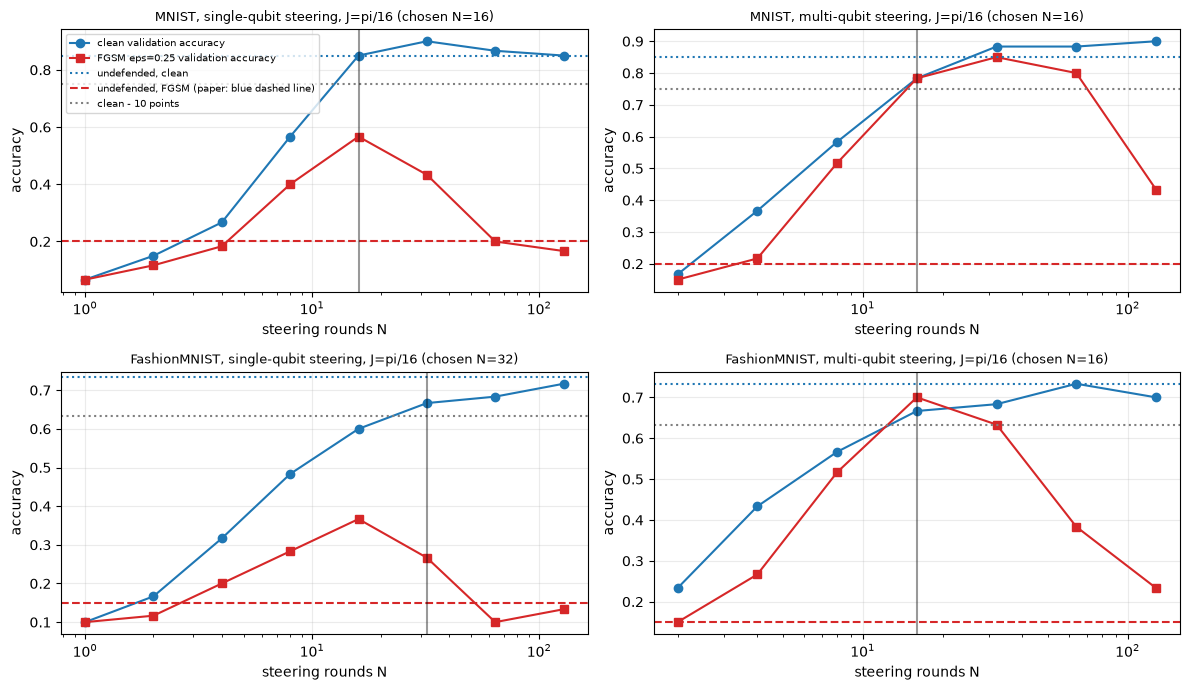

MNIST: chosen N (single-qubit) = 16, (multi-qubit) = 16  | paper Table II: (pi/16, 27) and (pi/16, 40)
FashionMNIST: chosen N (single-qubit) = 32, (multi-qubit) = 16  | paper Table II: (pi/16, 20) and (pi/16, 25)


In [15]:
# Figures 10 / 11 analogues: accuracy against the number of steering rounds N (validation split, first seed)
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for r_, ds in enumerate(DATASETS):
    run = QNN_RUNS[ds][0]
    for c_, mode in enumerate(("S", "M")):
        ax = axes[r_, c_]; rows = np.array(run["sweeps"][mode]["rows"], dtype=float)
        ax.plot(rows[:, 0], rows[:, 1], "o-", label="clean validation accuracy"); ax.plot(rows[:, 0], rows[:, 2], "s-", color="C3", label=f"FGSM eps={EPS_SWEEP_QNN} validation accuracy")
        ax.axhline(run["val_clean"], color="C0", ls=":", label="undefended, clean"); ax.axhline(run["val_adv_undef"], color="C3", ls="--", label="undefended, FGSM (paper: blue dashed line)")
        ax.axhline(run["val_clean"] - CLEAN_DROP_LIMIT, color="gray", ls=":", label="clean - 10 points")
        ax.axvline(run["sweeps"][mode]["N"], color="k", alpha=0.4); ax.set_xscale("log"); ax.set_xlabel("steering rounds N"); ax.set_ylabel("accuracy")
        ax.set_title(f"{PRETTY[ds]}, {'single' if mode == 'S' else 'multi'}-qubit steering, J=pi/16 (chosen N={run['sweeps'][mode]['N']})", fontsize=9)
        if r_ == 0 and c_ == 0: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
for ds in DATASETS:
    r0 = QNN_RUNS[ds][0]; print(f"{PRETTY[ds]}: chosen N (single-qubit) = {r0['N_S']}, (multi-qubit) = {r0['N_M']}  | paper Table II: "
          f"{'(pi/16, 27) and (pi/16, 40)' if ds == 'mnist' else '(pi/16, 20) and (pi/16, 25)'}")

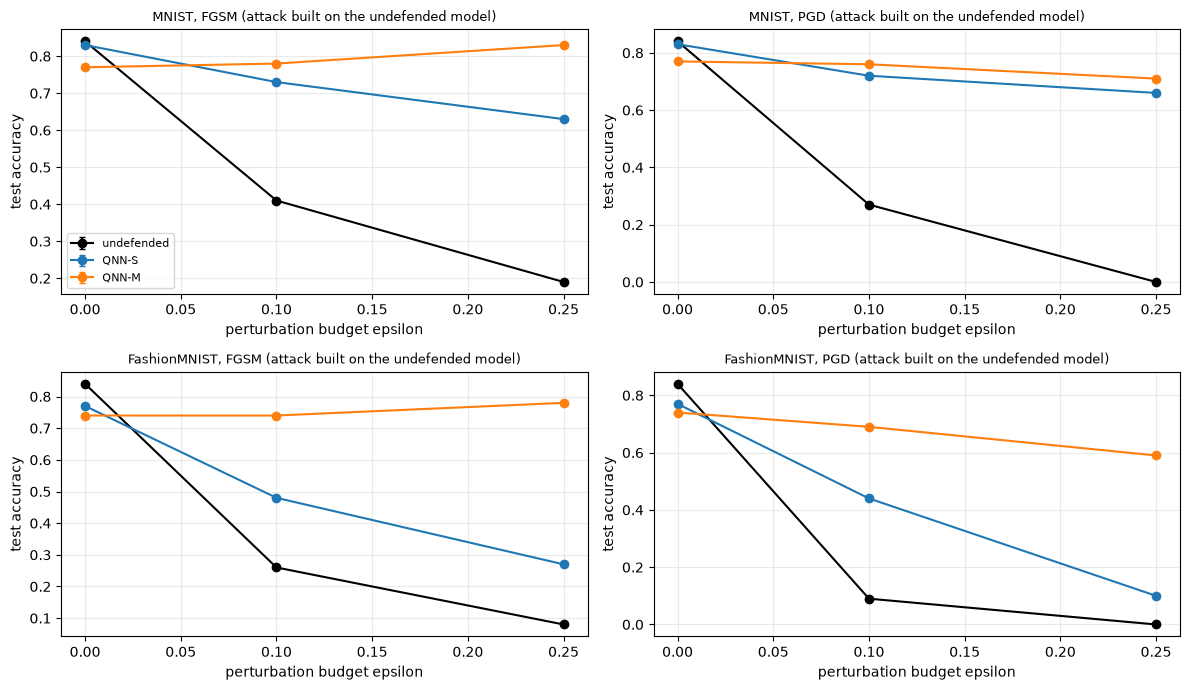

,dataset,encoder,N,clean,fgsm 0.1,fgsm 0.25,pgd 0.1,pgd 0.25
0,MNIST,undefended,-,0.840+-0.000,0.410+-0.000,0.190+-0.000,0.270+-0.000,0.000+-0.000
1,MNIST,QNN-S,16,0.830+-0.000,0.730+-0.000,0.630+-0.000,0.720+-0.000,0.660+-0.000
2,MNIST,QNN-M,16,0.770+-0.000,0.780+-0.000,0.830+-0.000,0.760+-0.000,0.710+-0.000
3,FashionMNIST,undefended,-,0.840+-0.000,0.260+-0.000,0.080+-0.000,0.090+-0.000,0.000+-0.000
4,FashionMNIST,QNN-S,32,0.770+-0.000,0.480+-0.000,0.270+-0.000,0.440+-0.000,0.100+-0.000
5,FashionMNIST,QNN-M,16,0.740+-0.000,0.740+-0.000,0.780+-0.000,0.690+-0.000,0.590+-0.000


In [16]:
# Accuracy against the perturbation budget (Fig. 12 analogue), mean +- std over seeds
def agg(runs, model, cond):
    v = np.array([r["acc"][model][cond] for r in runs]); return v.mean(), v.std()

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for r_, ds in enumerate(DATASETS):
    for c_, kind in enumerate(("fgsm", "pgd")):
        ax = axes[r_, c_]; runs = QNN_RUNS[ds]
        e0 = [0.0] + EPS_QNN
        for m, col in (("undefended", "k"), ("QNN-S", "C0"), ("QNN-M", "C1")):
            mu = [agg(runs, m, ("clean", None))[0]] + [agg(runs, m, (kind, e))[0] for e in EPS_QNN]
            sd = [agg(runs, m, ("clean", None))[1]] + [agg(runs, m, (kind, e))[1] for e in EPS_QNN]
            ax.errorbar(e0, mu, yerr=sd, marker="o", color=col, label=m, capsize=2)
        ax.set_xlabel("perturbation budget epsilon"); ax.set_ylabel("test accuracy"); ax.set_title(f"{PRETTY[ds]}, {kind.upper()} (attack built on the undefended model)", fontsize=9)
        if r_ == 0 and c_ == 0: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for ds in DATASETS:
    runs = QNN_RUNS[ds]
    for m in ("undefended", "QNN-S", "QNN-M"):
        d = {"dataset": PRETTY[ds], "encoder": m, "N": "-" if m == "undefended" else int(np.mean([r["N_S" if m == "QNN-S" else "N_M"] for r in runs]))}
        mu, sd = agg(runs, m, ("clean", None)); d["clean"] = f"{mu:.3f}+-{sd:.3f}"
        for kind in ("fgsm", "pgd"):
            for e in EPS_QNN:
                mu, sd = agg(runs, m, (kind, e)); d[f"{kind} {e}"] = f"{mu:.3f}+-{sd:.3f}"
        rows.append(d)
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
QNN_TABLE = pd.DataFrame(rows); QNN_TABLE

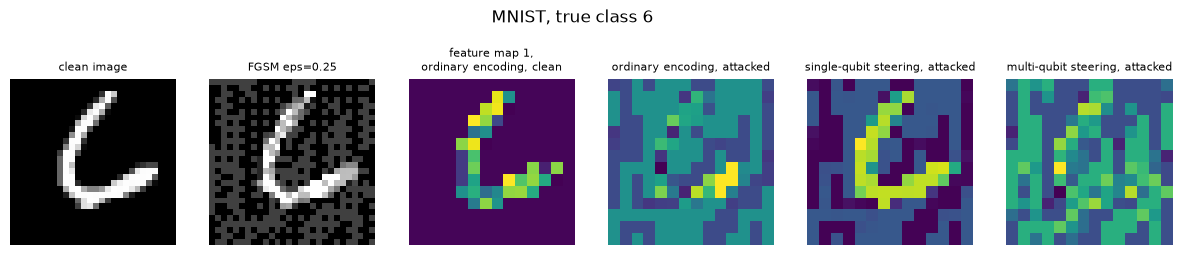

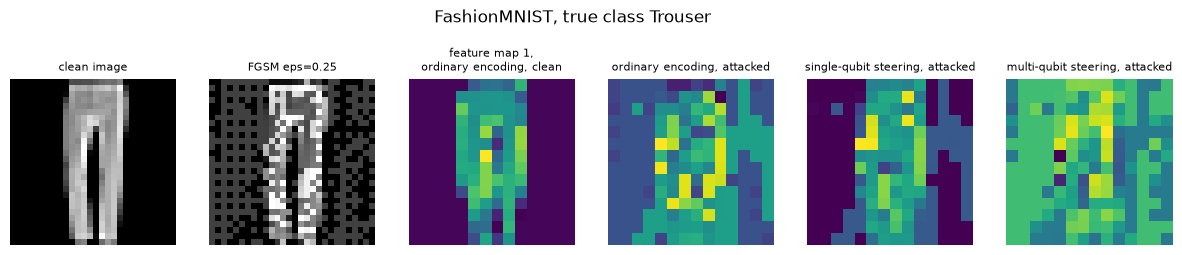

In [17]:
# Fig. 9 analogue: the first quanvolution feature map of one attacked test image through the three encoders
for ds in DATASETS:
    dm = QNN_RUNS[ds][0].get("demo")
    if dm is None: continue
    fig, axes = plt.subplots(1, 6, figsize=(15, 2.8))
    for ax, (img, ttl) in zip(axes, [(dm["x"], "clean image"), (dm["xa"], f"FGSM eps={EPS_QNN[-1]}"), (dm["f_clean"], "feature map 1,\nordinary encoding, clean"),
                                       (dm["f_adv"], "ordinary encoding, attacked"), (dm["f_S"], "single-qubit steering, attacked"), (dm["f_M"], "multi-qubit steering, attacked")]):
        ax.imshow(img, cmap="gray" if img.shape[0] == 28 else "viridis"); ax.set_title(ttl, fontsize=8); ax.axis("off")
    plt.suptitle(f"{PRETTY[ds]}, true class {LABEL_NAMES[ds][dm['label']]}", y=1.04); plt.show()

## 5. The fully quantum classifiers (QCNN and VQC, amplitude encoding)

The 16x16 binary subsets (classes 0 and 1 of each dataset) are amplitude-embedded in 8 qubits. The VQC and the QCNN output
`<Z>` of the last qubit; the class-1 probability is `p = (1 + <Z>)/2` and the models are trained with binary cross-entropy (Adam).

**Defence.** The amplitude embedding is replaced by amplitude steering (Section 3): the register starts in `|0...0>` and is steered
towards the normalised image for only `N` rounds with `J = pi/10`, while the classifier is left untouched. The `(J, N)` rule is the
same as before: the smallest `N` for which the validation clean accuracy falls by less than 10 points. The intermediate state is
mixed, so the classifier output is `Tr[O rho_N]` with `O = W^dagger Z W` (W = classifier unitary). The steering of one image
costs `N` rounds of 256 x 256 density-matrix updates, which is why the subsets are small.

In [18]:
QC_LOSS = lambda z, y: F.binary_cross_entropy(((1 + z) / 2).clamp(1e-6, 1 - 1e-6), y.double(), reduction="sum")   # CHOICE: p = (1+<Z>)/2
BATCH_QC = 32 if FAST_MODE else 64

def train_qc(kind, xtr, ytr, seed):
    torch.manual_seed(seed)
    if kind == "VQC":
        params = [(0.1 * torch.randn(3, NQA, 3)).requires_grad_(True)]; fn = lambda x: vqc_qnode(x, *params)
    else:
        params = [(0.3 * torch.randn(N_CONV, 3)).requires_grad_(True), (0.3 * torch.randn(N_POOL, 3)).requires_grad_(True)]; fn = lambda x: qcnn_qnode(x, *params)
    opt = torch.optim.Adam(params, lr=0.05); g = torch.Generator().manual_seed(seed)
    for s in range(STEPS_QC):
        idx = torch.randint(0, len(xtr), (BATCH_QC,), generator=g); z = fn(xtr[idx])
        loss = QC_LOSS(z, ytr[idx]) / BATCH_QC; opt.zero_grad(); loss.backward(); opt.step()
    return fn, [p.detach() for p in params]

def qc_acc_from_z(z, y): return ((z > 0).long() == y).double().mean().item()
unit = lambda x: x / x.norm(dim=1, keepdim=True)

def run_qc(ds, seed, verbose=True):
    t0 = time.time(); sp = make_split_qc(ds, seed); (xtr, ytr), (xva, yva), (xte, yte) = sp["train"], sp["val"], sp["test"]
    models, obs = {}, {}
    for kind in ("VQC", "QCNN"):
        fn, par = train_qc(kind, xtr, ytr, seed); models[kind] = (fn, par)
        body = (lambda p=par: vqc_body(p[0])) if kind == "VQC" else (lambda p=par: qcnn_body(p[0], p[1]))
        obs[kind] = body_matrix(body)
        with torch.no_grad(): z = fn(xva)
        # the density-matrix observable O = W^dagger Z W reproduces the QNode on pure states
        assert torch.allclose(torch.einsum("ab,nb,na->n", obs[kind], unit(xva).to(torch.complex64), unit(xva).to(torch.complex64)).real.double(), z, atol=2e-5)
        if verbose: print(f"[{PRETTY[ds]} {kind}] trained ({time.time() - t0:.0f}s) | val acc {qc_acc_from_z(z, yva):.3f}, test acc {qc_acc_from_z(fn(xte).detach(), yte):.3f}")
    O2 = torch.stack([obs["VQC"], obs["QCNN"]]); st = AmpSteer(J_QC)
    # ---- selection of N on the validation split (clean accuracy; both models share the steered states) ----
    base_val = {k: qc_acc_from_z(models[k][0](xva).detach(), yva) for k in models}
    zs = st.run(unit(xva), O2, N_GRID_QC)
    sweep = {k: [(N, qc_acc_from_z(zs[N][:, j], yva)) for N in N_GRID_QC] for j, k in enumerate(("VQC", "QCNN"))}
    Nsel = {}
    for k in sweep:
        ok = [r for r in sweep[k] if base_val[k] - r[1] < CLEAN_DROP_LIMIT]; Nsel[k] = min(ok)[0] if ok else max(N_GRID_QC)
        if verbose: print(f"   {k}: chosen N = {Nsel[k]}" + ("" if ok else "  (constraint not met: largest N used)"))
    # ---- test: white-box attacks on the undefended model; then the defended encoder sees the same adversarial images ----
    acc = {k: {"undefended": {}, "steered": {}} for k in models}
    zc = st.run(unit(xte), O2, set(Nsel.values()))
    for j, k in enumerate(("VQC", "QCNN")):
        fn = models[k][0]
        acc[k]["undefended"][("clean", None)] = qc_acc_from_z(fn(xte).detach(), yte)
        acc[k]["steered"][("clean", None)] = qc_acc_from_z(zc[Nsel[k]][:, j], yte)
        for kind in ("fgsm", "pgd"):
            for eps in EPS_QC:
                xa = attack(fn, xte, yte, eps, kind, QC_LOSS, bs=40)
                acc[k]["undefended"][(kind, eps)] = qc_acc_from_z(fn(xa).detach(), yte)
                zz = st.run(unit(xa), O2[j:j + 1], [Nsel[k]])[Nsel[k]][:, 0]
                acc[k]["steered"][(kind, eps)] = qc_acc_from_z(zz, yte)
        if verbose: print(f"   {k}: PGD eps={EPS_QC[-1]}  undefended {acc[k]['undefended'][('pgd', EPS_QC[-1])]:.3f}  steered {acc[k]['steered'][('pgd', EPS_QC[-1])]:.3f}  ({time.time() - t0:.0f}s)")
    return {"ds": ds, "models": models, "obs": obs, "N": Nsel, "sweep": sweep, "base_val": base_val, "acc": acc, "test": (xte, yte), "val": (xva, yva), "time": time.time() - t0}

QC_RUNS = {ds: run_qc(ds, SEEDS[0]) for ds in DATASETS}      # one seed: the density-matrix evaluation is the expensive part

[MNIST VQC] trained (26s) | val acc 1.000, test acc 1.000


[MNIST QCNN] trained (58s) | val acc 1.000, test acc 1.000


   VQC: chosen N = 16
   QCNN: chosen N = 8


   VQC: PGD eps=0.1  undefended 0.850  steered 0.850  (130s)


   QCNN: PGD eps=0.1  undefended 0.825  steered 0.800  (161s)


[FashionMNIST VQC] trained (29s) | val acc 0.933, test acc 1.000


[FashionMNIST QCNN] trained (69s) | val acc 0.933, test acc 0.975


   VQC: chosen N = 6
   QCNN: chosen N = 6


   VQC: PGD eps=0.1  undefended 0.825  steered 0.675  (112s)


   QCNN: PGD eps=0.1  undefended 0.600  steered 0.425  (139s)


In [19]:
# Check the exact Kraus-iteration executor against the reference circuit with real reset (default.mixed, 9 qubits), VQC model, 2 images
run = QC_RUNS["mnist"]; w = run["models"]["VQC"][1][0]; xte = run["test"][0][:2]; N_chk = 3
dev_m9 = qml.device("default.mixed", wires=NQA + 1)
ref_amp = qml.QNode(lambda V, J, N: amp_steer_reference(V, J, N, lambda: vqc_body(w.numpy()), "channel"), dev_m9)
Vs = householder(unit(xte))
z_ref = np.array([float(ref_amp(Vs[i].numpy(), J_QC, N_chk)) for i in range(2)])
z_exec = AmpSteer(J_QC).run(unit(xte), run["obs"]["VQC"][None], [N_chk])[N_chk][:, 0].numpy()
print("reference circuit :", np.round(z_ref, 6)); print("executor          :", np.round(z_exec, 6))
assert np.allclose(z_ref, z_exec, atol=2e-5)
print("amplitude-steering executor == reference circuit with reset channel (N=3, VQC, 2 images)")

reference circuit : [-0.117631 -0.101123]
executor          : [-0.117631 -0.101123]
amplitude-steering executor == reference circuit with reset channel (N=3, VQC, 2 images)


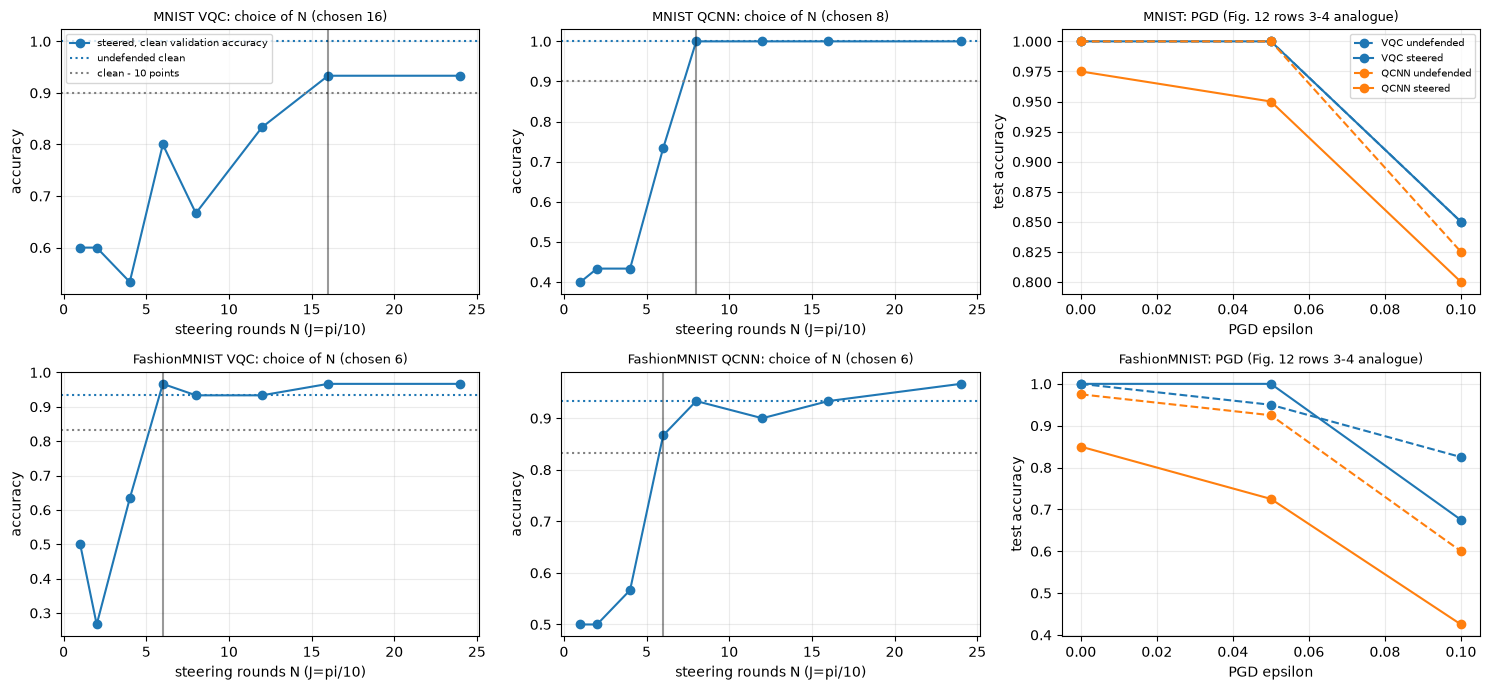

,dataset,model,encoder,N,clean,fgsm 0.05,fgsm 0.1,pgd 0.05,pgd 0.1
0,MNIST,VQC,undefended,-,1.000,1.000,0.900,1.000,0.850
1,MNIST,VQC,steered,16,1.000,1.000,0.850,1.000,0.850
2,MNIST,QCNN,undefended,-,1.000,1.000,0.875,1.000,0.825
3,MNIST,QCNN,steered,8,0.975,0.950,0.800,0.950,0.800
4,FashionMNIST,VQC,undefended,-,1.000,0.950,0.825,0.950,0.825
5,FashionMNIST,VQC,steered,6,1.000,1.000,0.800,1.000,0.675
6,FashionMNIST,QCNN,undefended,-,0.975,0.925,0.625,0.925,0.600
7,FashionMNIST,QCNN,steered,6,0.850,0.725,0.400,0.725,0.425


In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for r_, ds in enumerate(DATASETS):
    run = QC_RUNS[ds]
    for c_, k in enumerate(("VQC", "QCNN")):
        ax = axes[r_, c_]; rows = np.array(run["sweep"][k], dtype=float)
        ax.plot(rows[:, 0], rows[:, 1], "o-", label="steered, clean validation accuracy"); ax.axhline(run["base_val"][k], color="C0", ls=":", label="undefended clean")
        ax.axhline(run["base_val"][k] - CLEAN_DROP_LIMIT, color="gray", ls=":", label="clean - 10 points"); ax.axvline(run["N"][k], color="k", alpha=0.4)
        ax.set_xlabel("steering rounds N (J=pi/10)"); ax.set_ylabel("accuracy"); ax.set_title(f"{PRETTY[ds]} {k}: choice of N (chosen {run['N'][k]})", fontsize=9)
        if r_ == 0 and c_ == 0: ax.legend(fontsize=7)
    ax = axes[r_, 2]; e0 = [0.0] + EPS_QC
    for k, col in (("VQC", "C0"), ("QCNN", "C1")):
        for variant, ls in (("undefended", "--"), ("steered", "-")):
            a = run["acc"][k][variant]; ax.plot(e0, [a[("clean", None)]] + [a[("pgd", e)] for e in EPS_QC], ls=ls, marker="o", color=col, label=f"{k} {variant}")
    ax.set_xlabel("PGD epsilon"); ax.set_ylabel("test accuracy"); ax.set_title(f"{PRETTY[ds]}: PGD (Fig. 12 rows 3-4 analogue)", fontsize=9)
    if r_ == 0: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
rows = []
for ds in DATASETS:
    for k in ("VQC", "QCNN"):
        for variant in ("undefended", "steered"):
            a = QC_RUNS[ds]["acc"][k][variant]; d = {"dataset": PRETTY[ds], "model": k, "encoder": variant, "N": "-" if variant == "undefended" else QC_RUNS[ds]["N"][k], "clean": round(a[("clean", None)], 3)}
            for kind in ("fgsm", "pgd"):
                for e in EPS_QC: d[f"{kind} {e}"] = round(a[(kind, e)], 3)
            rows.append(d)
QC_TABLE = pd.DataFrame(rows); QC_TABLE

## 6. Classical baselines on the same inputs, and an adaptive attacker (extras beyond the paper)

**Classical baselines.** The paper has none. On the identical inputs we train (i) a random forest and an RBF-SVM, (ii) for the
QNN task a classical CNN in which the quantum filter is replaced by a classical 2x2 convolution (4 learned filters, then the same
head), and for the binary tasks a small MLP (256-16-1). The CNN and the MLP are attacked with the same FGSM and PGD. This tells
the reader how fragile an *undefended classical* model is, and whether the quantum models are unusually brittle or robust.

**Adaptive attacker.** The paper's attacker knows the undefended model only. A stronger attacker knows that the encoder is
the steering circuit with the chosen `N`, and differentiates *through the defended encoder* (single-qubit steering, which is
differentiable here). If the defence were only masking gradients, this attacker would erase its gain.

In [21]:
class ClassicalCNN(nn.Module):
    def __init__(self):
        super().__init__(); self.q = nn.Conv2d(1, 4, 2, stride=2); self.head = Head(4)
    def forward(self, x): return self.head(torch.tanh(self.q(x.reshape(-1, 1, 28, 28))))
class MLP(nn.Module):
    def __init__(self):
        super().__init__(); self.net = nn.Sequential(nn.Linear(256, 16), nn.ReLU(), nn.Linear(16, 1))
    def forward(self, x): return torch.tanh(self.net(x)).squeeze(-1)           # output in (-1,1) like <Z>

BASE_ROWS = []
for ds in DATASETS:
    # ---- QNN task (10 classes, 28x28) ----
    sp = make_split_qnn(ds, SEEDS[0]); (xtr, ytr), (xte, yte) = sp["train"], sp["test"]
    cnn = fit(ClassicalCNN(), xtr, ytr, SEEDS[0], EPOCHS_QNN)
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(xtr.reshape(len(xtr), -1).numpy(), ytr.numpy())
    svm = SVC(kernel="rbf", C=10, gamma="scale").fit(xtr.reshape(len(xtr), -1).numpy(), ytr.numpy())
    d = {"task": f"{PRETTY[ds]} 10 classes", "model": "classical CNN (2x2 conv, same head)", "clean": acc_of(cnn, xte, yte)}
    for kind in ("fgsm", "pgd"):
        for e in EPS_QNN: d[f"{kind} {e}"] = acc_of(cnn, attack(cnn, xte, yte, e, kind, CE_SUM), yte)
    BASE_ROWS.append(d)
    BASE_ROWS.append({"task": f"{PRETTY[ds]} 10 classes", "model": "random forest (clean only)", "clean": rf.score(xte.reshape(len(xte), -1).numpy(), yte.numpy())})
    BASE_ROWS.append({"task": f"{PRETTY[ds]} 10 classes", "model": "SVC rbf (clean only)", "clean": svm.score(xte.reshape(len(xte), -1).numpy(), yte.numpy())})
    # ---- binary 16x16 task ----
    sb = make_split_qc(ds, SEEDS[0]); (xtr, ytr), (xte, yte) = sb["train"], sb["test"]
    torch.manual_seed(SEEDS[0]); mlp = MLP(); opt = torch.optim.Adam(mlp.parameters(), lr=0.02)
    for s in range(300):
        idx = torch.randint(0, len(xtr), (64,)); loss = QC_LOSS(mlp(xtr[idx]), ytr[idx]) / 64; opt.zero_grad(); loss.backward(); opt.step()
    d = {"task": f"{PRETTY[ds]} binary 16x16", "model": "classical MLP 256-16-1", "clean": qc_acc_from_z(mlp(xte).detach(), yte)}
    for kind in ("fgsm", "pgd"):
        for e in EPS_QC: d[f"{kind} {e}"] = qc_acc_from_z(mlp(attack(mlp, xte, yte, e, kind, QC_LOSS, bs=100)).detach(), yte)
    BASE_ROWS.append(d)
    rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1).fit(xtr.numpy(), ytr.numpy()); svm = SVC(kernel="rbf", C=10, gamma="scale").fit(xtr.numpy(), ytr.numpy())
    BASE_ROWS.append({"task": f"{PRETTY[ds]} binary 16x16", "model": "random forest (clean only)", "clean": rf.score(xte.numpy(), yte.numpy())})
    BASE_ROWS.append({"task": f"{PRETTY[ds]} binary 16x16", "model": "SVC rbf (clean only)", "clean": svm.score(xte.numpy(), yte.numpy())})
BASE_TABLE = pd.DataFrame(BASE_ROWS).round(3); BASE_TABLE

,task,model,clean,fgsm 0.1,fgsm 0.25,pgd 0.1,pgd 0.25,fgsm 0.05,pgd 0.05
0,MNIST 10 classes,"classical CNN (2x2 conv, same head)",0.940,0.640,0.01,0.550,0.0,NaN,NaN
1,MNIST 10 classes,random forest (clean only),0.970,NaN,NaN,NaN,NaN,NaN,NaN
2,MNIST 10 classes,SVC rbf (clean only),0.960,NaN,NaN,NaN,NaN,NaN,NaN
3,MNIST binary 16x16,classical MLP 256-16-1,1.000,0.875,NaN,0.775,NaN,1.000,1.000
4,MNIST binary 16x16,random forest (clean only),1.000,NaN,NaN,NaN,NaN,NaN,NaN
5,MNIST binary 16x16,SVC rbf (clean only),1.000,NaN,NaN,NaN,NaN,NaN,NaN
6,FashionMNIST 10 classes,"classical CNN (2x2 conv, same head)",0.810,0.270,0.01,0.200,0.0,NaN,NaN
7,FashionMNIST 10 classes,random forest (clean only),0.820,NaN,NaN,NaN,NaN,NaN,NaN
8,FashionMNIST 10 classes,SVC rbf (clean only),0.790,NaN,NaN,NaN,NaN,NaN,NaN
9,FashionMNIST binary 16x16,classical MLP 256-16-1,0.975,0.575,NaN,0.750,NaN,0.925,0.875


In [22]:
# Adaptive attacker against single-qubit steering (QNN): gradients flow through the defended encoder (PennyLane back-propagation).
ADAPT = []
for ds in DATASETS:
    run = QNN_RUNS[ds][0]; head = run["head"]; xte, yte = run["test"]; n = N_ADAPT; xs, ys = xte[:n], yte[:n]
    Je = jeff(J_QNN, run["N_S"])
    defended = lambda x, grad=False: head(qfeat(x, "S", Je, grad=grad))
    undef = lambda x, grad=False: head(qfeat(x, "base", grad=grad))
    for kind, eps in (("fgsm", EPS_QNN[-1]), ("pgd", EPS_QNN[0] if 0.1 not in EPS_QNN else 0.1)):
        t0 = time.time()
        xa_trans = attack(lambda x: undef(x, True), xs, ys, eps, kind, CE_SUM, bs=n)           # paper's attacker (undefended model)
        xa_adapt = attack(lambda x: defended(x, True), xs, ys, eps, kind, CE_SUM, bs=4)      # adaptive attacker (defended encoder)
        with torch.no_grad():
            a = lambda f, x: (f(x).argmax(1) == ys).double().mean().item()
            ADAPT.append({"dataset": PRETTY[ds], "attack": f"{kind.upper()} eps={eps}", "images": n, "undefended model, paper attack": a(undef, xa_trans),
                          "defended, paper attack": a(defended, xa_trans), "defended, ADAPTIVE attack": a(defended, xa_adapt), "clean, defended": a(defended, xs)})
        print(ADAPT[-1]["dataset"], ADAPT[-1]["attack"], f"({time.time() - t0:.0f}s)")
ADAPT_TABLE = pd.DataFrame(ADAPT).round(3); ADAPT_TABLE

MNIST FGSM eps=0.25 (8s)


MNIST PGD eps=0.1 (121s)


FashionMNIST FGSM eps=0.25 (11s)


FashionMNIST PGD eps=0.1 (77s)


,dataset,attack,images,"undefended model, paper attack","defended, paper attack","defended, ADAPTIVE attack","clean, defended"
0,MNIST,FGSM eps=0.25,8,0.375,1.000,0.625,1.0
1,MNIST,PGD eps=0.1,8,0.500,1.000,1.000,1.0
2,FashionMNIST,FGSM eps=0.25,8,0.125,0.375,0.125,1.0
3,FashionMNIST,PGD eps=0.1,8,0.125,0.625,0.250,1.0


## 7. Side by side with the paper (Table III and the text claims)

Sign convention of the paper's Table III: the first number is the change in clean accuracy (negative = the defended model is worse),
the second the gain in adversarial accuracy under PGD with `epsilon = 0.1`, both in percentage points. The tolerance for
"reproduced" is 2 percentage points. The test subsets are small (see the configuration cell), so one test image is worth
1/`N_TEST` of accuracy and differences of a few points are within sampling noise; the verdicts must be read with that in mind.

In [23]:
PAPER_T3 = {("QNN-S", "mnist"): (-1.67, 6.50), ("QNN-S", "fmnist"): (-7.84, 40.19), ("QNN-M", "mnist"): (-0.89, 0.01), ("QNN-M", "fmnist"): (-9.05, 24.59),
            ("QCNN", "mnist"): (-0.19, 17.64), ("QCNN", "fmnist"): (0.75, 6.35), ("VQC", "mnist"): (-0.05, 33.05), ("VQC", "fmnist"): (-0.05, 4.55)}

def verdict(ours, paper, tol=2.0):
    gap = ours - paper
    if abs(gap) <= tol: return "reproduced"
    return f"not reached (gap {gap:+.1f} pts)" if gap < 0 else f"exceeded (gap {gap:+.1f} pts)"

def ours_t3(model, ds):
    """(clean change, PGD eps=0.1 gain) of the defended vs the undefended model, percentage points."""
    if model in ("QNN-S", "QNN-M"):
        runs = QNN_RUNS[ds]; d = lambda cond: np.mean([r["acc"][model][cond] - r["acc"]["undefended"][cond] for r in runs]) * 100
        return d(("clean", None)), d(("pgd", 0.1))
    a = QC_RUNS[ds]["acc"][model]; d = lambda cond: (a["steered"][cond] - a["undefended"][cond]) * 100
    return d(("clean", None)), d(("pgd", 0.1))

rows, T3 = [], {}
for (model, ds), (pc, pa) in PAPER_T3.items():
    oc, oa = ours_t3(model, ds); T3[(model, ds)] = (oc, oa)
    rows.append({"model": model, "dataset": PRETTY[ds], "paper (clean change, PGD gain)": f"({pc:+.2f}, {pa:+.2f})", "this notebook": f"({oc:+.2f}, {oa:+.2f})",
                 "clean change < 10 points drop": "reproduced" if oc > -10 else f"not reached ({oc:+.1f})", "PGD gain verdict": verdict(oa, pa), "gain > 0": "yes" if oa > 0 else "no"})
TABLE3 = pd.DataFrame(rows); TABLE3

,model,dataset,"paper (clean change, PGD gain)",this notebook,clean change < 10 points drop,PGD gain verdict,gain > 0
0,QNN-S,MNIST,"(-1.67, +6.50)","(-1.00, +45.00)",reproduced,exceeded (gap +38.5 pts),yes
1,QNN-S,FashionMNIST,"(-7.84, +40.19)","(-7.00, +35.00)",reproduced,not reached (gap -5.2 pts),yes
2,QNN-M,MNIST,"(-0.89, +0.01)","(-7.00, +49.00)",reproduced,exceeded (gap +49.0 pts),yes
3,QNN-M,FashionMNIST,"(-9.05, +24.59)","(-10.00, +60.00)",reproduced,exceeded (gap +35.4 pts),yes
4,QCNN,MNIST,"(-0.19, +17.64)","(-2.50, -2.50)",reproduced,not reached (gap -20.1 pts),no
5,QCNN,FashionMNIST,"(+0.75, +6.35)","(-12.50, -17.50)",not reached (-12.5),not reached (gap -23.9 pts),no
6,VQC,MNIST,"(-0.05, +33.05)","(+0.00, +0.00)",reproduced,not reached (gap -33.0 pts),no
7,VQC,FashionMNIST,"(-0.05, +4.55)","(+0.00, -15.00)",reproduced,not reached (gap -19.5 pts),no


In [24]:
claims = []
add = lambda claim, paper, ours, v: claims.append({"claim": claim, "paper": paper, "this notebook": ours, "verdict": v})

# 1. headline and Table III as a whole
gains = [v[1] for v in T3.values()]; drops = [v[0] for v in T3.values()]
add("Table III, defence raises PGD(eps=0.1) accuracy in every model/dataset", "8 of 8 cells > 0 (up to +40.19)", f"{sum(g > 0 for g in gains)} of 8 cells > 0 (max {max(gains):+.1f})",
    "reproduced" if all(g > 0 for g in gains) else ("partially reproduced" if sum(g > 0 for g in gains) >= 4 else "not reached"))
add("Headline: gain of up to 40.19 points", "+40.19 (QNN-S, FashionMNIST)", f"largest gain here {max(gains):+.1f}", verdict(max(gains), 40.19))
add("Clean accuracy falls by less than 10 points in every cell", "max drop 9.05", f"max drop here {-min(drops):.1f}", "reproduced" if min(drops) > -10 else "not reached")

# 2. Section IV-C text, QNN-S at eps = 0.25
e = EPS_QNN[-1]
if abs(e - 0.25) < 1e-9:
    for ds, p_und, p_fg, p_pg, p_cl in (("mnist", 0.65, 13, 44, 2), ("fmnist", 0.23, 62, 96, 8)):
        runs = QNN_RUNS[ds]; m = lambda mod, cond: np.mean([r["acc"][mod][cond] for r in runs])
        und = m("undefended", ("fgsm", e)); add(f"QNN undefended FGSM accuracy at eps=0.25, {PRETTY[ds]}", f"{p_und:.2f}", f"{und:.2f}", verdict(und * 100, p_und * 100))
        g = (m("QNN-S", ("fgsm", e)) - und) * 100; add(f"QNN-S FGSM gain at eps=0.25, {PRETTY[ds]} (units of the paper unclear: points assumed)", f"+{p_fg}", f"{g:+.1f}", verdict(g, p_fg))
        g = (m("QNN-S", ("pgd", e)) - m("undefended", ("pgd", e))) * 100; add(f"QNN-S PGD gain at eps=0.25, {PRETTY[ds]} (units unclear: points assumed)", f"+{p_pg}", f"{g:+.1f}", verdict(g, p_pg))
        c = (m("undefended", ("clean", None)) - m("QNN-S", ("clean", None))) * 100; add(f"QNN-S clean accuracy drop, {PRETTY[ds]}", f"{p_cl} points", f"{c:.1f} points", verdict(c, p_cl))

# 3. qualitative claims
def interior_peak(rows):
    r = np.array(rows, dtype=float); i = int(np.argmax(r[:, 2])); return 0 < i < len(r) - 1 or (i == 0 and r[-1, 2] < r[0, 2] - 0.02)
pk = [interior_peak(QNN_RUNS[ds][0]["sweeps"]["S"]["rows"]) for ds in DATASETS]
add("Fig. 11: adversarial accuracy rises with N, peaks and then falls (single-qubit steering)", "yes (3 datasets)", f"peak then decline in {sum(pk)} of {len(pk)} datasets (validation FGSM)", "reproduced" if all(pk) else ("partially reproduced" if any(pk) else "not reached"))
mo = [QNN_RUNS[ds][0]["N_M"] > QNN_RUNS[ds][0]["N_S"] for ds in DATASETS]
add("Table II: multi-qubit steering needs a larger N than single-qubit steering", "40 > 27 and 25 > 20", ", ".join(f"{PRETTY[ds]}: N_M={QNN_RUNS[ds][0]['N_M']} vs N_S={QNN_RUNS[ds][0]['N_S']}" for ds in DATASETS), "reproduced" if all(mo) else "not reached")
add("Fig. 7: J = pi/2 reaches the exact target state in one round", "yes", "fidelity 1.0 after N=1 (assertion in Section 2, PennyLane circuit)", "reproduced")
add("Table II values of (J, N) transfer", "N=27/20 (S), 40/25 (M), 10/12 (QCNN), 20/18 (VQC)", f"chosen here: S {[QNN_RUNS[d][0]['N_S'] for d in DATASETS]}, M {[QNN_RUNS[d][0]['N_M'] for d in DATASETS]}, QCNN {[QC_RUNS[d]['N']['QCNN'] for d in DATASETS]}, VQC {[QC_RUNS[d]['N']['VQC'] for d in DATASETS]}",
    "cannot be checked (the steering Hamiltonian and start state are not specified, so N is not transferable)")
add("QCNN has 72 trainable parameters (48 conv + 24 pool)", "72", f"{3 * (N_CONV + N_POOL)} (layout unspecified in the paper)", "not reached (layout is a choice)")
add("Adversarial robustness when the attacker knows the defence", "not studied", "see the adaptive-attack table in Section 6", "cannot be checked (extra result)")
COMPARISON = pd.DataFrame(claims)
pd.set_option("display.max_colwidth", 90); COMPARISON

,claim,paper,this notebook,verdict
0,"Table III, defence raises PGD(eps=0.1) accuracy in every model/dataset",8 of 8 cells > 0 (up to +40.19),4 of 8 cells > 0 (max +60.0),partially reproduced
1,Headline: gain of up to 40.19 points,"+40.19 (QNN-S, FashionMNIST)",largest gain here +60.0,exceeded (gap +19.8 pts)
2,Clean accuracy falls by less than 10 points in every cell,max drop 9.05,max drop here 12.5,not reached
3,"QNN undefended FGSM accuracy at eps=0.25, MNIST",0.65,0.19,not reached (gap -46.0 pts)
4,"QNN-S FGSM gain at eps=0.25, MNIST (units of the paper unclear: points assumed)",+13,+44.0,exceeded (gap +31.0 pts)
5,"QNN-S PGD gain at eps=0.25, MNIST (units unclear: points assumed)",+44,+66.0,exceeded (gap +22.0 pts)
6,"QNN-S clean accuracy drop, MNIST",2 points,1.0 points,reproduced
7,"QNN undefended FGSM accuracy at eps=0.25, FashionMNIST",0.23,0.08,not reached (gap -15.0 pts)
8,"QNN-S FGSM gain at eps=0.25, FashionMNIST (units of the paper unclear: points assumed)",+62,+19.0,not reached (gap -43.0 pts)
9,"QNN-S PGD gain at eps=0.25, FashionMNIST (units unclear: points assumed)",+96,+10.0,not reached (gap -86.0 pts)


In [25]:
# Compact numeric summary (small, printed for the record)
print("Table III analogue (clean change, PGD eps=0.1 gain), points:")
for k, v in T3.items(): print(f"  {k[0]:6s} {PRETTY[k[1]]:13s} paper {PAPER_T3[k]}  notebook ({v[0]:+.2f}, {v[1]:+.2f})")
print("Adaptive attack:"); print(ADAPT_TABLE.to_string(index=False))
print("seeds", SEEDS, "| FAST_MODE", FAST_MODE)

Table III analogue (clean change, PGD eps=0.1 gain), points:
  QNN-S  MNIST         paper (-1.67, 6.5)  notebook (-1.00, +45.00)
  QNN-S  FashionMNIST  paper (-7.84, 40.19)  notebook (-7.00, +35.00)
  QNN-M  MNIST         paper (-0.89, 0.01)  notebook (-7.00, +49.00)
  QNN-M  FashionMNIST  paper (-9.05, 24.59)  notebook (-10.00, +60.00)
  QCNN   MNIST         paper (-0.19, 17.64)  notebook (-2.50, -2.50)
  QCNN   FashionMNIST  paper (0.75, 6.35)  notebook (-12.50, -17.50)
  VQC    MNIST         paper (-0.05, 33.05)  notebook (+0.00, +0.00)
  VQC    FashionMNIST  paper (-0.05, 4.55)  notebook (+0.00, -15.00)
Adaptive attack:
     dataset        attack  images  undefended model, paper attack  defended, paper attack  defended, ADAPTIVE attack  clean, defended
       MNIST FGSM eps=0.25       8                           0.375                   1.000                      0.625              1.0
       MNIST   PGD eps=0.1       8                           0.500                   1.000        

### What the committed run shows (FAST_MODE, seed 42, small test subsets: indications, not precise estimates)

* **Hybrid QNN: direction reproduced, magnitude not.** The undefended QNN collapses under the white-box attacks (PGD at
  `epsilon = 0.25`: 0 % accuracy on both datasets), as the paper reports. Behind the steered encoders, with the *same* trained
  head, accuracy stays much higher: for PGD at `epsilon = 0.1` the gain is +45 / +35 points for single-qubit steering and
  +49 / +60 points for multi-qubit steering (MNIST / FashionMNIST), with a clean-accuracy loss of 1 to 10 points. The paper's
  gains are +6.5 / +40.2 (S) and +0.0 / +24.6 (M), so MNIST gains are far larger here, FashionMNIST single-qubit is close.
  These differences are expected: our steering protocol, start state and quantum filter are our own choices.
* **Fig. 11 shape reproduced.** On the validation split the adversarial accuracy rises with `N`, peaks and then falls back
  towards the undefended value (both datasets, both steering types), and the clean accuracy rises monotonically with `N`.
* **Fully quantum models: not reproduced.** For the amplitude-encoded QCNN and VQC the steered encoder gives no gain in this
  implementation (MNIST: -2.5 and 0 points; FashionMNIST: -17.5 and -15 points, with a clean drop of 12.5 points for the QCNN),
  while the paper reports +17.6 / +6.4 (QCNN) and +33.1 / +4.6 (VQC). Our undefended QCNN/VQC are also less vulnerable than the paper's
  (PGD at 0.1 leaves 60 to 85 % accuracy). Possible reasons: the Householder encoding unitary and the cooling interaction are choices
  the paper does not specify, the test subsets have only 40 images per cell, and the claim may not carry over; the notebook cannot tell.
* **Classical baselines.** The classical CNN with the same head loses less under the same PGD at `epsilon = 0.1` (55 % MNIST, 20 %
  FashionMNIST) than the undefended QNN (27 %, 9 %), so the very low undefended QNN accuracy is partly a property of this particular
  fixed random quantum filter. The MLP on the binary tasks (77 % / 75 % under PGD 0.1) is no more robust than the quantum models.
* **Adaptive attacker.** With 8 images per cell, knowing the defence removes part of the gain: FGSM at 0.25 on MNIST 100 % -> 62.5 %
  (undefended 37.5 %), FashionMNIST 37.5 % -> 12.5 % (undefended 12.5 %); PGD at 0.1 on FashionMNIST 62.5 % -> 25 % (undefended
  12.5 %), on MNIST the gain survives in this small sample (100 % -> 100 %). The gain of single-qubit steering is therefore at least partly
  a transfer effect of the attack, not robustness to an attacker who knows the defence. Eight images are too few for firm numbers.

## 8. Reading the paper critically

* **The attack is not aimed at the defence.** Adversarial examples are crafted against the *undefended* model and then shown to a
  *different* pipeline (the same classifier behind a steered encoder). That is a transfer (grey-box) attack. A defence can look
  strong here only because the attacker's gradient points in a direction that the defended encoder happens to damp. The adaptive
  attacker of Section 6 (who differentiates through the defended encoder) is the relevant test, and the paper has none. Read the
  adaptive-attack table before accepting any "improvement" as robustness.
* **The mechanism is a contraction of the input.** Stopping the steering early makes the encoded state a flatter function of the
  pixel (Section 2, right panel): small angles move the qubit less. Any shrinking of the input contrast also shrinks the
  perturbation, but it equally shrinks the signal, and that is why the clean accuracy drops and why `N` has to be tuned. The
  classical baselines show how a plain classical model behaves under the same attacks; a classical smoothing or quantisation of the
  input could play the same role without a quantum circuit. The paper does not compare against such a classical pre-processing.
* **`(J, N)` is tuned to the attack that is later reported.** Even when `N` is picked by clean accuracy only, the final `N` is the
  one that happens to lie in the range where FGSM accuracy peaks (Fig. 11), and the paper selects with part of the *test* set.
  Here a validation split of the training data is used; the choice rule is ours.
* **Unspecified steering model.** The Hamiltonian, the starting state, the QCNN layout and the quantum filter are not given, so
  Table II's `N` values do not transfer and the exact gains of Table III are not expected to match, only their direction.
* **Resource cost.** Single-qubit steering needs one ancilla per qubit and `N` rounds of mid-circuit measurement and reset each;
  multi-qubit steering needs `N` times more rounds. On hardware, every round adds noise and latency that the paper's noiseless
  simulation ignores, and the defended state is mixed, so the classifier sees an ensemble average. The amplitude-steering cost in
  this notebook (a 256 x 256 density matrix updated `N` times per image) is also why only small subsets were run.
* **Evidence strength.** One run per cell, no confidence intervals, accuracy gains reported as "%" without saying whether they are
  absolute points or relative changes (the PGD gain of 96 % in the text cannot be an absolute gain when the undefended accuracy
  drops by 80 %). Here, with small test subsets, a change of one test image is a few points.
* **Scope.** Only white-box gradient attacks on image classification with 10 classes (QNN) or 2 classes (QCNN, VQC); no noise, no
  other attack families, no real cybersecurity data. It is a study of adversarial robustness of quantum encoders, not an
  intrusion-detection result.

## 9. Exercises

1. **Strength versus rounds.** For the QNN, keep `N * (1 - cos(J))` roughly constant while changing `J` (try `J = pi/16, pi/8, pi/4`).
   Do the chosen `N`, the clean accuracy and the PGD gain change? Use the closed form `J_eff = arccos(cos(J)^N)` to explain why.
2. **Another starting state.** Section 2 starts the register in `|0>`. Change the starting state of the steering to `RY(pi/2)|0>`
   (a "grey" start) in `steer1_qnode` and the single-qubit reference circuit. How does the encoded `<Z>` curve of the right
   panel in Section 2 change, and does the defence still help?
3. **Adaptive attacker, stronger.** Extend the adaptive attack in Section 6 to the multi-qubit steering encoder (use the
   `multi_features` executor with `grad=True`, which is differentiable). Is it as vulnerable as the single-qubit version?
4. **Classical smoothing.** Replace the quantum steering by a classical pre-processor of your choice (e.g. blur the image with a
   3x3 mean filter, or round pixels to two levels) and repeat the PGD comparison with the same clean-accuracy budget of 10
   points. Is a quantum circuit needed to obtain the same robustness gain?
5. **Statistics.** Set `FAST_MODE = False` and add more seeds to `SEEDS`. Compute a 95 % bootstrap interval of the PGD gain for
   each cell of Table III. Which of the paper's cells are statistically distinguishable from zero?